# CAISO Project-Realization Classifier (Cluster 14 and Prior)

**Question this notebook answers:** *For a project entering the CAISO interconnection queue, what is the
probability that it eventually **reaches commercial operation before it withdraws**?*

This is the machine-learning (ML) tool of an agentic interconnection-risk assistant. The agent combines three tools:

| Tool | What it contributes |
|---|---|
| SQL database | Facts and comparables: similar historical projects, queue statistics, CAISO production and curtailment context |
| **ML model (this notebook)** | A calibrated probability that a project reaches operation before withdrawal, plus a risk tier |
| RAG over documents | Policy and process context (tariff rules, cluster study reports, deliverability) |

**Scope.** This is a *development and interconnection realization* risk signal. It is **not** an approval/rejection
forecast (CAISO does not publish such a label here) and **not** a full investment-underwriting model (it ignores
offtake, financing, equipment quality, resource quality, and O&M).

**How to read this notebook.** Every section opens with a short note on its purpose, why it matters, and key terms.
Every result is followed by a plain-language **Interpretation** cell. Judgment calls are labeled **Decision**.
Reusable logic lives in `Scripts/caiso_ml_data.py` (data and features) and `Scripts/caiso_ml_eval.py` (metrics and plots).

**Sections**
1. Framing and setup
2. Load the workbook and check data quality
3. Label maturity: choosing the queue-year cutoff from the active sheet
4. Train / test / validation split and the frozen validation holdout
5. Leakage audit
6. Queue-entry features and a single-feature leakage screen
7. Associations with the outcome (training data only)
8. Outliers and transformations
9. `queue_year` ablation
10. Models: baseline, Logistic Regression, Random Forest, XGBoost, CatBoost (tuning and calibration)
11. Threshold optimization on out-of-fold predictions
12. Test-set evaluation (all technologies and solar)
13. Validating the "maximize true positives, minimize false positives" objective
14. Robustness: cutoff sensitivity and a time-based check
15. Interpretation: odds ratios, permutation importance, SHAP, partial dependence
16. Model selection, saved artifacts, and the scoring helper
17. Final thoughts and recommendations

**Order note.** The split (Section 4) comes *before* the leakage audit, feature screen, and association analysis so that
every analysis that looks at outcomes uses training projects only. This differs slightly from the order in the
build plan; it is stricter, not looser.

## 1. Framing and setup

**Purpose.** Define the target precisely and load the libraries and project scripts.

**Why it matters.** A model is only useful if everyone reads its output the same way. Our label comes from which
sheet of the CAISO workbook a project appears on:

* `reached_operation = 1`: the project is on the **Completed Generation Projects** sheet (it reached commercial operation).
* `reached_operation = 0`: the project is on the **Withdrawn Generation Projects** sheet (it left the queue).
* Projects on the **Grid GenerationQueue** (active) sheet have **no final outcome yet**. In survival-analysis terms they are
  **right-censored**: we know they have survived *so far*, not how they end. They are **never** labeled. They are used only to
  measure how mature each queue cohort's labels are (Section 3) and as scoring examples (Section 16).

**Key terms.**
* *Leakage*: using information in a feature that would not be known when the prediction is made (here: at queue entry).
  Leakage makes a model look excellent in testing and useless in practice.
* *Calibrated probability*: a probability that can be read literally (among projects scored 0.30, about 30% reach operation).
* *Association vs. cause*: every relationship found here is historical correlation. Nothing in this notebook shows that changing
  a feature would change a project's outcome.

**Future extension (not built here).** A competing-risks survival model would use active projects properly by modeling
*time to operation* versus *time to withdrawal* while respecting censoring.

In [1]:
import sys
import json
import hashlib
import platform
import warnings
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import loguniform

import sklearn
import xgboost
import catboost
import shap
from catboost import Pool
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Project scripts: data preparation (caiso_ml_data) and evaluation (caiso_ml_eval).
sys.path.insert(0, str(Path("..") / "Scripts"))
import caiso_ml_data as cd
import caiso_ml_eval as ce

SEED = 42  # one seed for every split, search, and model so results are reproducible
DATA_PATH = Path("../Data_ML_SQL/CASIO_Cluster_14_and_Prior_Interconnection_Requests.xlsx")
MODELS_DIR = Path("../Models")
MODELS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| catboost", catboost.__version__, "| shap", shap.__version__)

python 3.12.9 | sklearn 1.9.1 | xgboost 3.4.1 | catboost 1.2.10 | shap 0.52.0


## 2. Load the workbook and check data quality

**Purpose.** Load all three sheets with the same cleaning used in the EDA notebook (three title rows skipped, the
`Report Run Date` column and the disclaimer row removed, snake_case column names) and check basic integrity.

**Why it matters.** A project listed on two sheets would have two contradictory labels; impossible dates would become
misleading features. The active sheet is loaded here only so Section 3 can count unresolved projects.

**Key terms.**
* *Requested horizon*: years between queue entry and the online date the developer requested in the application.
* *IR receipt date*: when CAISO received the interconnection request; the queue date normally follows it.

In [2]:
projects = cd.load_workbook(DATA_PATH)

sheet_summary = projects.groupby("source_sheet").agg(
    projects=(cd.ID_COLUMN, "size"),
    first_queue_year=("queue_year", "min"),
    last_queue_year=("queue_year", "max"),
    solar_projects=("is_solar", "sum"),
)
display(sheet_summary)

quality = cd.data_quality_report(projects)
display(quality)

# Hard integrity checks: every project appears once and has a queue date.
assert projects[cd.ID_COLUMN].is_unique, "A queue position appears on more than one sheet."
assert projects["queue_date"].notna().all(), "Some projects have no queue date."
print(f"{len(projects):,} projects loaded; IDs unique across sheets; every project has a queue date.")

,projects,first_queue_year,last_queue_year,solar_projects
source_sheet,,,,
Completed Generation Projects,252,1999,2021,134
Grid GenerationQueue,262,2003,2021,87
Withdrawn Generation Projects,1764,2000,2023,830


,sheet,projects,duplicate_ids_within_sheet,ids_also_on_other_sheet,missing_queue_date,requested_online_before_queue,queue_date_before_ir_receipt
0,Completed Generation Projects,252,0,0,0,5,4
1,Grid GenerationQueue,262,0,0,0,0,0
2,Withdrawn Generation Projects,1764,0,0,0,2,112


2,278 projects loaded; IDs unique across sheets; every project has a queue date.


**Interpretation.** The workbook holds 2,278 projects: 252 operational, 1,764 withdrawn, and 262 active. No queue position
appears twice and every project has a queue date, so each resolved project has exactly one label.

Two date problems appear:
* **7 projects requested an online date before their queue date** (5 completed, 2 withdrawn). Feature engineering treats
  these horizons as invalid (set to missing and flagged by `horizon_invalid`) rather than trusting them.
* **116 projects have a queue date more than a week before CAISO received the request**, and **112 of them are on the
  withdrawn sheet**. A real data-entry error would not care about the eventual outcome, so this lopsidedness suggests the
  two sheets were maintained differently. Section 6 tests whether it leaks the outcome. The active sheet has none of
  either problem.

The withdrawn sheet also contains 6 projects queued in 2022-2023 that withdrew quickly. They are too few to form a cohort and
fall after the cutoff chosen below.

## 3. Label maturity: choosing the queue-year cutoff from the active sheet

**Purpose.** Decide which queue years have labels mature enough to train on.

**Why it matters.** Withdrawals tend to happen within a few years of queue entry, while reaching commercial operation
usually takes five or more years. For a recent queue year, many future successes are still on the active sheet, so the
*resolved* projects from that year are mostly quick withdrawals. Training on them would teach the model that recent
projects almost never succeed, an artifact of timing rather than a real pattern. This is the **recent-year skew toward
withdrawal**.

**Method.** For each queue year, count active, operational, and withdrawn projects and compute:

* `active_share = active / total`: how much of the cohort is still unresolved (the label-maturity measure).
* `operational_rate_resolved = operational / (operational + withdrawn)`: the success rate a classifier would learn from that year.

**Cutoff rule (`cd.choose_cutoff_year`).** Among years with at least 20 projects, the cutoff **Y** is the last year whose
active share is at or below a tolerance, with every later year above it. The main model uses a **10%** tolerance; 5% and
20% are shown for comparison. Resolved projects queued in or before Y form the **mature cohort** used for modeling.
Resolved projects queued after Y form the **immature cohort**, which is reported separately and never used for training.

**Key term.** *Tolerance*: the largest unresolved share we accept. At 10%, at most about one in ten projects in an included
cohort could still change the label mix.

All technologies: outcomes by queue year


outcome,active,operational,withdrawn,total,active_share,operational_rate_resolved
queue_year,,,,,,
1999,0,1,0,1,0.000,1.000
2000,0,4,4,8,0.000,0.500
2001,0,0,1,1,0.000,0.000
2002,0,2,1,3,0.000,0.667
2003,1,6,4,11,0.091,0.600
2004,1,8,20,29,0.034,0.286
2005,4,9,17,30,0.133,0.346
2006,4,14,61,79,0.051,0.187
2007,3,15,116,134,0.022,0.115


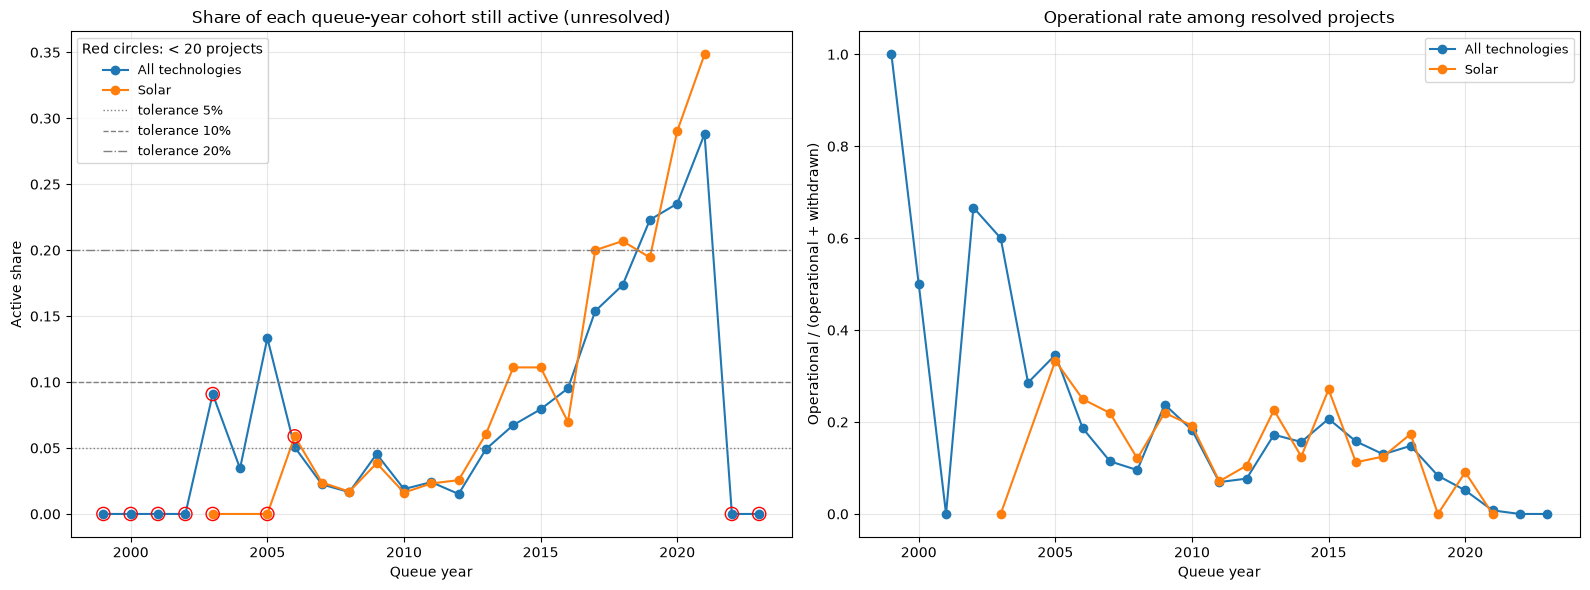

In [3]:
maturity_all = cd.maturity_table(projects)
maturity_solar = cd.maturity_table(projects[projects["is_solar"]])
print("All technologies: outcomes by queue year")
display(maturity_all)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for table, label in [(maturity_all, "All technologies"), (maturity_solar, "Solar")]:
    small = table["total"] < 20
    axes[0].plot(table.index, table["active_share"], marker="o", label=label)
    axes[0].scatter(table.index[small], table.loc[small, "active_share"], s=90, facecolors="none",
                    edgecolors="red", zorder=3)
    axes[1].plot(table.index, table["operational_rate_resolved"], marker="o", label=label)
for tol, style in [(0.05, ":"), (0.10, "--"), (0.20, "-.")]:
    axes[0].axhline(tol, color="gray", ls=style, lw=1, label=f"tolerance {tol:.0%}")
axes[0].set(title="Share of each queue-year cohort still active (unresolved)", xlabel="Queue year",
            ylabel="Active share")
axes[1].set(title="Operational rate among resolved projects", xlabel="Queue year",
            ylabel="Operational / (operational + withdrawn)")
axes[0].legend(title="Red circles: < 20 projects", fontsize=9)
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

**Interpretation.**
* **Left panel:** the active share stays at or below 10% for every cohort through 2016. The one exception is 2005 (13%, only
  30 projects, a few very long-running older projects). After 2016 it climbs steadily: 15% (2017), 17% (2018), 22% (2019),
  24% (2020), and 29% (2021). Solar crosses earlier and higher, reaching 35% in 2021. The 2022-2023 points show 0% only because
  those 6 projects are all quick withdrawals; the 20-project minimum keeps them from affecting the rule.
* **Right panel:** among resolved projects, the operational rate hovers around 15% for 2013-2018, then falls to 8% (2019),
  5% (2020), and **0.8% (2021)**. It falls exactly where the active share rises.

The two panels together are the recent-year skew. Recent cohorts have not had time to reach operation, so their resolved
projects are mostly early withdrawals. A model trained on 2021 labels would learn that 2021-era projects almost never succeed,
which reflects timing rather than project quality.

In [4]:
resolved = cd.resolved_projects(projects)
TOLERANCES = [0.05, 0.10, 0.20]
MAIN_TOLERANCE = 0.10
MIN_PROJECTS_PER_YEAR = 20


def cohort_counts(frame):
    # Size and operational counts for a cohort, overall and for solar.
    solar = frame[frame["is_solar"]]
    return {
        "projects": len(frame), "operational": int(frame[cd.TARGET].sum()),
        "operational_rate": frame[cd.TARGET].mean(),
        "solar_projects": len(solar), "solar_operational": int(solar[cd.TARGET].sum()),
    }


rows = []
for tol in TOLERANCES:
    year = cd.choose_cutoff_year(maturity_all, tolerance=tol, min_projects=MIN_PROJECTS_PER_YEAR)
    rows.append({"tolerance": tol, "cutoff_year": year,
                 **cohort_counts(resolved[resolved["queue_year"] <= year]),
                 "resolved_projects_excluded": int((resolved["queue_year"] > year).sum())})
cutoff_table = pd.DataFrame(rows)
display(cutoff_table)

CUTOFF_YEAR = int(cutoff_table.loc[cutoff_table["tolerance"] == MAIN_TOLERANCE, "cutoff_year"].iloc[0])
CUTOFF_RULE = (f"Last queue year (among years with >= {MIN_PROJECTS_PER_YEAR} projects) whose active share is "
               f"<= {MAIN_TOLERANCE:.0%}, with every later year above that tolerance (all technologies).")
print(f"Main-model cutoff year Y = {CUTOFF_YEAR}")
print("Rule:", CUTOFF_RULE)

,tolerance,cutoff_year,projects,operational,operational_rate,solar_projects,solar_operational,resolved_projects_excluded
0,0.050,2013,1057,158,0.149,647,97,959
1,0.100,2016,1370,213,0.155,807,123,646
2,0.200,2018,1528,235,0.154,870,132,488


Main-model cutoff year Y = 2016
Rule: Last queue year (among years with >= 20 projects) whose active share is <= 10%, with every later year above that tolerance (all technologies).


**Interpretation.**
* **5% tolerance gives Y = 2013**: 1,057 mature projects, 158 operational.
* **10% tolerance gives Y = 2016**: 1,370 projects, 213 operational. **This is the main model.**
* **20% tolerance gives Y = 2018**: 1,528 projects, 235 operational.

Moving from 10% to 20% adds 158 projects but only 22 operational ones, and it admits cohorts where up to 17% of projects are
still unresolved. Moving from 10% to 5% throws away 313 projects (55 of them operational, a quarter of all positives) for a
small gain in maturity. The 10% rule is the balance point.

The operational rate is about 15% under all three cutoffs, so the label mix of the training data is similar either way. Section 14
shows that the cutoff matters much more for the *level* of predictions on recent projects than for ranking accuracy.

**Decision: main-model cutoff.** The main model trains only on resolved projects queued in or before **Y** (the
10%-tolerance year above). The cutoff is computed from all technologies rather than solar alone because the model trains on
all technologies, and a solar-only table has fewer projects per year and noisier shares. Section 14 tests Y-2, Y+2, and
no cutoff to show how much this choice matters.

In [5]:
mature, immature = cd.split_by_cutoff(resolved, CUTOFF_YEAR)

cohorts = pd.DataFrame({
    "All resolved": cohort_counts(resolved),
    f"Mature (queued <= {CUTOFF_YEAR}): modeling cohort": cohort_counts(mature),
    f"Immature (queued > {CUTOFF_YEAR}): reported only": cohort_counts(immature),
}).T
display(cohorts)

print("Immature cohort by queue year (labels skew toward withdrawal while many projects are still active):")
display(maturity_all.loc[maturity_all.index > CUTOFF_YEAR,
                         ["active", "operational", "withdrawn", "active_share", "operational_rate_resolved"]])

assert set(mature["outcome"]) <= {"operational", "withdrawn"}, "Active projects leaked into the modeling cohort."
assert (mature["queue_year"] <= CUTOFF_YEAR).all() and (immature["queue_year"] > CUTOFF_YEAR).all()

,projects,operational,operational_rate,solar_projects,solar_operational
All resolved,2016.000,252.000,0.125,964.000,134.000
Mature (queued <= 2016): modeling cohort,1370.000,213.000,0.155,807.000,123.000
Immature (queued > 2016): reported only,646.000,39.000,0.060,157.000,11.000


Immature cohort by queue year (labels skew toward withdrawal while many projects are still active):


outcome,active,operational,withdrawn,active_share,operational_rate_resolved
queue_year,,,,,
2017,14,10,67,0.154,0.130
2018,17,12,69,0.173,0.148
2019,31,9,99,0.223,0.083
2020,36,6,111,0.235,0.051
2021,104,2,255,0.288,0.008
2022,0,0,2,0.000,0.000
2023,0,0,4,0.000,0.000


**Interpretation.** The **mature cohort** has 1,370 projects with 213 operational (**15.5%**), including 807 solar projects
(123 operational). The **immature cohort** has 646 resolved projects with only **6.0%** operational, less than half the mature
rate. 2021 alone has 255 withdrawals, 2 operational projects, and 104 projects still active.

Excluding the immature cohort costs 39 positive labels but removes 607 withdrawal labels, many of which are likely premature
relative to the eventual successes. Note also that the "all resolved" rate (12.5%) would understate how often projects historically
reach operation, because it mixes in these unfinished cohorts.

## 4. Train / test / validation split and the frozen validation holdout

**Purpose.** Divide the mature cohort into three sets *before* any analysis that looks at outcomes.

| Set | Share | Used for |
|---|---|---|
| Train | 60% | Association analysis, outlier bounds, tuning, calibration, out-of-fold predictions, threshold choice |
| Test | 30% | One final, unbiased comparison of the trained models |
| Validation | 10% | **Untouched.** Reserved for evaluating the full agent later |

**Why it matters.** If test or validation projects influence any modeling choice, their scores stop being honest
estimates of performance on new projects.

**Method.** The split is stratified by both `reached_operation` and `is_solar`, so each set keeps nearly the same operational
rate and solar share. The validation set is drawn first. Its queue positions are saved to
`Models/validation_holdout_ids.csv`; on re-runs the notebook checks that the saved IDs have not changed.

**Key term.** *Stratified split*: a random split that keeps the proportion of each group (here: outcome by solar) the same in every set.

In [6]:
splits = cd.stratified_three_way_split(mature, 0.60, 0.30, 0.10, seed=SEED)
train_df = mature.loc[splits["train"]].copy()
test_df = mature.loc[splits["test"]].copy()
val_df = mature.loc[splits["validation"]].copy()

split_summary = pd.DataFrame({name: cohort_counts(frame) for name, frame in
                              [("train", train_df), ("test", test_df), ("validation", val_df)]}).T
split_summary["share_of_mature"] = split_summary["projects"] / len(mature)
display(split_summary)

# Freeze the validation holdout: write it once, then verify it on every re-run.
HOLDOUT_PATH = MODELS_DIR / "validation_holdout_ids.csv"
holdout = (val_df[[cd.ID_COLUMN, "queue_year", "fuel_1", "is_solar", "study_process", cd.TARGET]]
           .sort_values(cd.ID_COLUMN, key=lambda s: s.astype(str)).reset_index(drop=True))
if HOLDOUT_PATH.exists():
    saved_ids = set(pd.read_csv(HOLDOUT_PATH)[cd.ID_COLUMN].astype(str))
    assert saved_ids == set(holdout[cd.ID_COLUMN].astype(str)), "Validation holdout changed; investigate before continuing."
    print(f"Validation holdout verified against {HOLDOUT_PATH} ({len(saved_ids)} projects).")
else:
    holdout.to_csv(HOLDOUT_PATH, index=False)
    print(f"Validation holdout written to {HOLDOUT_PATH} ({len(holdout)} projects).")

for name, frame in [("train", train_df), ("test", test_df), ("validation", val_df)]:
    assert (frame["outcome"] != "active").all(), f"Active project in {name}"

,projects,operational,operational_rate,solar_projects,solar_operational,share_of_mature
train,821.000,128.000,0.156,483.000,74.000,0.599
test,412.000,64.000,0.155,243.000,37.000,0.301
validation,137.000,21.000,0.153,81.000,12.000,0.100


Validation holdout verified against ../Models/validation_holdout_ids.csv (137 projects).


**Interpretation.** The split is **821 / 412 / 137** projects (60 / 30 / 10%). The operational rate is 15.3-15.6% in all three
sets and the solar share is the same, so no set is easier than another by construction. The test set has 64 operational
projects (37 solar). That is enough to compare models, but individual metrics will carry wide uncertainty, so Section 12
reports bootstrap intervals.

**Validation holdout assessment.** The holdout has only **137 projects (21 operational, 12 operational solar)**, smaller than
the roughly 200 estimated in the plan because the cutoff shrank the labeled pool. That is too small to estimate model metrics
precisely: an AUC on 21 positives has a 95% interval roughly +/- 0.10 wide. It is better suited to **end-to-end agent
evaluation**: does the agent call the right tools, retrieve correct comparables, report the right tier, and explain the result
faithfully? The IDs are frozen in `Models/validation_holdout_ids.csv` and verified on every re-run.

## 5. Leakage audit

**Purpose.** Show that the excluded columns would leak the outcome, so excluding them is necessary rather than cautious.

**Why it matters.** Many CAISO columns are filled in *after* queue entry: study milestones, interconnection-agreement status,
deliverability allocation, online dates, and withdrawal details. Several are filled almost only for one outcome. A model using
them would score very well in testing and fail on new projects, where those fields are not yet known.

**Method.** For each excluded column, compare how often it is filled for operational and withdrawn training projects. The
*filled-indicator AUC* measures how well "is this field filled?" alone separates the two outcomes (0.5 = no information;
1.0 = perfect separation). The direction is ignored, so values run from 0.5 to 1.0.

**Key term.** *ROC-AUC*: the chance that a randomly chosen operational project ranks above a randomly chosen withdrawn one.

In [7]:
def symmetric_auc(y, score):
    # ROC-AUC with direction ignored (0.5 = no information, 1.0 = perfect separation).
    auc = roc_auc_score(y, score)
    return max(auc, 1 - auc)


y_train_raw = train_df[cd.TARGET].values
rows = []
for col, reason in cd.LEAKAGE_COLUMNS.items():
    if col not in train_df or col in {"outcome", "source_sheet", cd.ID_COLUMN, "project_name"}:
        continue
    filled = (train_df[col].notna() & train_df[col].astype(str).str.strip().ne("")).astype(int)
    rows.append({
        "column": col,
        "filled_share_operational": filled[y_train_raw == 1].mean(),
        "filled_share_withdrawn": filled[y_train_raw == 0].mean(),
        "filled_indicator_auc": symmetric_auc(y_train_raw, filled) if filled.nunique() > 1 else 0.5,
        "reason_excluded": reason,
    })
leakage_audit = pd.DataFrame(rows).sort_values("filled_indicator_auc", ascending=False)
with pd.option_context("display.max_colwidth", 90):
    display(leakage_audit)

,column,filled_share_operational,filled_share_withdrawn,filled_indicator_auc,reason_excluded
3,current_online_date,0.000,0.994,0.997,"Latest schedule, updated after queue entry; missing by sheet."
0,withdrawn_date,0.000,0.961,0.981,Only exists for withdrawn projects: directly reveals the outcome.
2,actual_online_date,0.961,0.000,0.980,Only exists for operational projects: directly reveals the outcome.
11,off_peak_deliverability,0.930,0.010,0.960,Deliverability result assigned after studies.
4,ia_status,0.969,0.069,0.950,"Interconnection-agreement status is a later milestone, not known at entry."
7,phase2_study,0.945,0.212,0.867,Study milestone reached after queue entry; missing mostly for withdrawals.
6,phase1_study,0.961,0.395,0.783,Study milestone reached after queue entry; missing mostly for withdrawals.
14,pto_study_region,0.414,0.000,0.707,Missing for about 94% of projects and assigned during studies.
1,reason_for_withdrawal,0.000,0.140,0.570,Only exists for withdrawn projects: directly reveals the outcome.
10,tpd_allocation_group,0.133,0.000,0.566,Deliverability allocation happens after studies; missing on the withdrawn sheet.


**Interpretation.** The excluded columns would leak the outcome almost perfectly:
* `current_online_date` is filled for 99% of withdrawn and 0% of operational projects (AUC 0.997). Operational projects carry an
  *actual* online date instead.
* `withdrawn_date` and `actual_online_date` (AUC 0.98) exist for only one outcome by definition.
* `off_peak_deliverability` (93% vs. 1%, AUC 0.96), `ia_status` (97% vs. 7%, AUC 0.95), and `phase2_study` (AUC 0.87) record
  milestones that only projects that progressed ever reach.
* `pto_study_region` is filled for 41% of operational and 0% of withdrawn projects.
* `application_status` is filled for everyone (AUC 0.5 here), but its *values* restate the sheet, i.e. the outcome.
  `suspension_status` is empty in the training data.

A model given any of these columns would look nearly perfect in testing and fail at queue entry, where these fields are blank
for every project. All of them are excluded, and `cd.assert_no_leakage` enforces this on every feature matrix.

## 6. Queue-entry features and a single-feature leakage screen

**Purpose.** Build features that use only information filed when the project entered the queue, then screen each feature for
hidden leakage.

**Why it matters.** A feature can be "known at entry" in principle but still leak if the two outcome sheets record it
differently. The EDA notebook found one candidate: about 112 withdrawn-sheet records (versus 4 completed-sheet records) have a
queue date more than a week *before* the request receipt date, which is impossible in reality and points to a sheet-specific
recording practice.

**Features** (built by `cd.engineer_features`, row by row, so this step cannot leak across projects):

| Feature | Meaning |
|---|---|
| `log_net_mw` | log(1 + requested MW to the grid); compresses the long right tail of project size |
| `n_components` | number of generating components filed (1 to 3) |
| `poi_kv`, `poi_kv_missing`, `poi_is_line` | voltage of the point of interconnection, whether it was written, and whether it is a line tap rather than a substation |
| `requested_horizon_years`, `horizon_invalid` | requested online date minus queue date (years); negative or > 15 years treated as data errors and flagged |
| `days_ir_to_queue` | days from request receipt to queue entry (screened below) |
| `queue_year` | calendar year of entry; an era proxy tested in Section 9 |
| `is_solar`, `is_hybrid`, `has_storage`, `zero_mw` | technology and configuration flags |
| `fuel_1`, `type_1`, `service_type`, `utility`, `state`, `county`, `study_group` | categories; `study_group` groups the 20+ study-process codes into cluster / serial / fast track / transition |

**Screen.** Each feature's single-feature AUC is computed on the training set. Categorical features use *out-of-fold target
encoding* (each project's category rate is computed from the other folds) so that rare categories cannot score well by
memorizing their own labels. A single queue-entry feature with AUC above about 0.80 would be suspicious.

In [8]:
features_train_all = cd.engineer_features(train_df)
cd.assert_no_leakage(features_train_all)
display(features_train_all.head())
display(features_train_all[cd.NUMERIC_FEATURES + cd.BINARY_FEATURES].describe().T)


def oof_target_encode(series, y, n_splits=5, smoothing=10, seed=SEED):
    # Out-of-fold smoothed category rate: each row is encoded using only the other folds.
    encoded = np.zeros(len(series))
    folds = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    values = series.to_numpy()
    for fit_idx, enc_idx in folds.split(values, y):
        prior = y[fit_idx].mean()
        stats_ = pd.DataFrame({"c": values[fit_idx], "y": y[fit_idx]}).groupby("c")["y"].agg(["sum", "count"])
        rate = (stats_["sum"] + smoothing * prior) / (stats_["count"] + smoothing)
        encoded[enc_idx] = pd.Series(values[enc_idx]).map(rate).fillna(prior).to_numpy()
    return encoded


rows = []
for col in features_train_all.columns:
    values = features_train_all[col]
    if col in cd.CATEGORICAL_FEATURES:
        score = oof_target_encode(values.astype(str), y_train_raw)
        missing = (values == "Missing").mean()
    else:
        score = values.fillna(values.median()).to_numpy()
        missing = values.isna().mean()
    rows.append({"feature": col, "kind": "categorical" if col in cd.CATEGORICAL_FEATURES else "numeric/binary",
                 "single_feature_auc": symmetric_auc(y_train_raw, score), "missing_share": missing})
screen = pd.DataFrame(rows).sort_values("single_feature_auc", ascending=False).reset_index(drop=True)
display(screen)

,log_net_mw,n_components,poi_kv,requested_horizon_years,days_ir_to_queue,queue_year,is_solar,is_hybrid,has_storage,zero_mw,horizon_invalid,poi_kv_missing,poi_is_line,fuel_1,type_1,service_type,utility,state,county,study_group
371,2.944,1,70.000,2.497,0.000,2010.000,1,0,0,0,0,0,1,Solar,Photovoltaic,Full Capacity,PGAE,CA,FRESNO,fast_track
1407,5.707,1,500.000,4.920,NaN,2013.000,1,0,0,0,0,0,1,Solar,Steam Turbine,Full Capacity,SDGE,AZ,MARICOPA,cluster
462,3.980,2,500.000,6.987,4.000,2016.000,0,1,1,0,0,0,0,Battery,Storage,Full Capacity,SDGE,AZ,MARICOPA,cluster
383,3.045,1,70.000,2.313,0.000,2010.000,1,0,0,0,0,0,0,Solar,Photovoltaic,Full Capacity,PGAE,CA,KINGS,fast_track
712,5.970,1,230.000,4.515,NaN,2007.000,0,0,0,0,0,0,0,Natural Gas,Reciprocating Engine,Missing,PGAE,CA,SOLANO,serial


,count,mean,std,min,25%,50%,75%,max
log_net_mw,821.000,4.390,1.400,0.000,3.045,4.587,5.505,8.007
n_components,821.000,1.074,0.272,1.000,1.000,1.000,1.000,3.000
poi_kv,758.000,171.844,107.094,12.000,70.000,138.000,230.000,500.000
requested_horizon_years,817.000,3.469,1.552,0.134,2.437,3.277,4.389,13.582
days_ir_to_queue,727.000,4.314,14.409,0.000,0.000,0.000,2.000,149.000
queue_year,821.000,2010.503,3.396,2000.000,2008.000,2010.000,2013.000,2016.000
is_solar,821.000,0.588,0.492,0.000,0.000,1.000,1.000,1.000
is_hybrid,821.000,0.072,0.258,0.000,0.000,0.000,0.000,1.000
has_storage,821.000,0.132,0.338,0.000,0.000,0.000,0.000,1.000
zero_mw,821.000,0.002,0.049,0.000,0.000,0.000,0.000,1.000


,feature,kind,single_feature_auc,missing_share
0,has_storage,numeric/binary,0.607,0.000
1,service_type,categorical,0.602,0.272
2,days_ir_to_queue,numeric/binary,0.593,0.114
3,fuel_1,categorical,0.577,0.004
4,study_group,categorical,0.574,0.000
5,is_hybrid,numeric/binary,0.573,0.000
6,n_components,numeric/binary,0.573,0.000
7,poi_kv,numeric/binary,0.568,0.077
8,log_net_mw,numeric/binary,0.559,0.000
9,county,categorical,0.548,0.000


**Interpretation.** No queue-entry feature comes close to the leaky columns. The strongest single-feature AUC is **0.61**
(`has_storage`), followed by `service_type` (0.60), `days_ir_to_queue` (0.59), `fuel_1` (0.58), and `study_group` (0.57). Each
feature is weak on its own, so any predictive power must come from combinations, which is consistent with the moderate
overall accuracy found later.

`days_ir_to_queue` ranks third even though a processing gap has no obvious reason to predict success. Given the date
problem found in Section 2, it gets a closer look in the next cell.

In [9]:
# Sheet-artifact check for days_ir_to_queue: raw gap before negative values are set to NaN.
raw_gap = (train_df["queue_date"] - train_df["ir_receive_date"]).dt.days
artifact = pd.DataFrame({
    "projects": train_df.groupby(cd.TARGET).size(),
    "queue_before_ir_by_7d_plus": (raw_gap < -7).groupby(train_df[cd.TARGET]).sum(),
    "share_queue_before_ir": (raw_gap < -7).groupby(train_df[cd.TARGET]).mean(),
    "median_gap_days_valid_only": raw_gap.where(raw_gap >= 0).groupby(train_df[cd.TARGET]).median(),
    "ir_date_missing_share": train_df["ir_receive_date"].isna().groupby(train_df[cd.TARGET]).mean(),
}).rename(index={0: "withdrawn (0)", 1: "operational (1)"})
display(artifact)

# Point-of-interconnection voltage missingness by outcome (a possible recording difference between sheets).
display(pd.crosstab(features_train_all["poi_kv_missing"], y_train_raw, normalize="columns")
        .rename(columns={0: "withdrawn", 1: "operational"}, index={0: "kV written", 1: "kV missing"}))

share_wd = artifact.loc["withdrawn (0)", "share_queue_before_ir"]
share_op = artifact.loc["operational (1)", "share_queue_before_ir"]
assert share_wd > 3 * share_op, "The impossible-date pattern is no longer sheet-specific; revisit the decision below."

,projects,queue_before_ir_by_7d_plus,share_queue_before_ir,median_gap_days_valid_only,ir_date_missing_share
reached_operation,,,,,
withdrawn (0),693,65,0.094,0.000,0.006
operational (1),128,1,0.008,0.000,0.000


col_0,withdrawn,operational
poi_kv_missing,,
kV written,0.919,0.945
kV missing,0.081,0.055


**Interpretation.** In the training set, **9.4% of withdrawn projects (65) have an impossible queue-before-receipt date,
versus 0.8% of operational projects (1)**. Among valid gaps, the median is 0 days for both outcomes. Nearly all of the
feature's signal therefore comes from the error pattern: those values become missing and are then imputed, which marks the
record as withdrawn-sheet. This is a trace of how the withdrawn sheet was maintained, not something known when a project
entered the queue. The active sheet, which supplies the projects the agent will score, has **zero** such errors, so the
signal would never appear at scoring time.

`poi_kv_missing` differs only slightly by outcome (8.1% vs. 5.5% missing). A withdrawn application being slightly less
complete is plausible and the effect is small, so it is kept.

In [10]:
# Decision (explained in the next cell): drop features whose values reflect sheet-specific recording.
DROP_FEATURES = {
    "days_ir_to_queue": ("Impossible queue-before-receipt dates occur almost only on the withdrawn sheet, so the gap "
                         "partly records which sheet a project is on rather than anything known at queue entry."),
}
print("Dropped features:", list(DROP_FEATURES))

Dropped features: ['days_ir_to_queue']


**Decision: drop `days_ir_to_queue`.** The cost is one weak feature. The benefit is removing a channel that would inflate
test metrics through a sheet-recording artifact and would not exist for new projects. `poi_kv_missing` is kept. Two more
features are evaluated for removal below: `is_hybrid` (redundancy, Section 7) and `queue_year` (era proxy, Section 9).

## 7. Associations with the outcome (training data only)

**Purpose.** Describe how each feature relates to reaching operation, and find redundant features.

**Why it matters.** This builds intuition, checks that the relationships are plausible, and flags features that carry the same
information (which makes Logistic Regression coefficients unstable). It does **not** select features. Every model receives
the same feature set, and regularization and tree splits decide what matters.

**Methods.**
* *Numeric features*: median by outcome, Mann-Whitney U test (do the two distributions differ?), and point-biserial correlation
  (correlation between a numeric feature and a 0/1 outcome).
* *Binary and categorical features*: operational rate by group, chi-square test of independence, and **Cramér's V**
  (association strength from 0 to 1 for categorical variables).
* *Mutual information*: how much knowing a feature reduces uncertainty about the outcome; it captures non-linear relationships.
* *Spearman correlation* between features: rank correlation; |rho| > 0.7 marks a near-duplicate.

p-values are descriptive. With dozens of tests, a few small p-values are expected by chance.

In [11]:
FEATURES_SCREENED = [c for c in features_train_all.columns if c not in DROP_FEATURES]
num_cols = [c for c in cd.NUMERIC_FEATURES if c in FEATURES_SCREENED]
bin_cols = [c for c in cd.BINARY_FEATURES if c in FEATURES_SCREENED]
cat_cols = [c for c in cd.CATEGORICAL_FEATURES if c in FEATURES_SCREENED]
Xa = features_train_all[FEATURES_SCREENED]
y = y_train_raw

numeric_assoc = []
for col in num_cols:
    values = Xa[col]
    ok = values.notna()
    numeric_assoc.append({
        "feature": col,
        "median_operational": values[y == 1].median(), "median_withdrawn": values[y == 0].median(),
        "mann_whitney_p": stats.mannwhitneyu(values[ok & (y == 1)], values[ok & (y == 0)]).pvalue,
        "point_biserial_r": stats.pointbiserialr(y[ok], values[ok])[0],
    })
print("Numeric features")
display(pd.DataFrame(numeric_assoc))


def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


categorical_assoc = []
for col in bin_cols + cat_cols:
    table = pd.crosstab(Xa[col], y)
    rate = pd.Series(y, index=Xa.index).groupby(Xa[col]).mean()
    categorical_assoc.append({
        "feature": col, "levels": table.shape[0],
        "chi2_p": stats.chi2_contingency(table)[1], "cramers_v": cramers_v(table),
        "highest_rate_level": f"{rate.idxmax()} ({rate.max():.2f})", "lowest_rate_level": f"{rate.idxmin()} ({rate.min():.2f})",
    })
print("Binary and categorical features")
display(pd.DataFrame(categorical_assoc).sort_values("cramers_v", ascending=False))

# Mutual information: numeric features median-imputed, categoricals as integer codes flagged as discrete.
mi_frame = Xa.copy()
for col in num_cols:
    mi_frame[col] = mi_frame[col].fillna(mi_frame[col].median())
for col in cat_cols:
    mi_frame[col] = mi_frame[col].astype("category").cat.codes
discrete = [c in bin_cols + cat_cols for c in mi_frame.columns]
mi = pd.Series(mutual_info_classif(mi_frame, y, discrete_features=discrete, random_state=SEED),
               index=mi_frame.columns).sort_values(ascending=False)
print("Mutual information with reached_operation (nats)")
display(mi.to_frame("mutual_information"))

Numeric features


,feature,median_operational,median_withdrawn,mann_whitney_p,point_biserial_r
0,log_net_mw,4.290,4.604,0.035,-0.081
1,n_components,1.000,1.000,0.000,0.192
2,poi_kv,230.000,115.000,0.013,0.038
3,requested_horizon_years,3.242,3.302,0.289,-0.053
4,queue_year,2010.000,2010.000,0.739,-0.011


Binary and categorical features


,feature,levels,chi2_p,cramers_v,highest_rate_level,lowest_rate_level
12,county,65,0.197,0.299,TUOLUMNE (1.00),BUTTE (0.00)
9,service_type,4,0.000,0.278,Partial Capacity (0.85),Energy Only (0.07)
7,fuel_1,11,0.000,0.231,Missing (1.00),Flywheel (0.00)
2,has_storage,2,0.000,0.225,1 (0.37),0 (0.12)
1,is_hybrid,2,0.000,0.199,1 (0.42),0 (0.14)
13,study_group,4,0.000,0.174,transition (0.42),serial (0.11)
8,type_1,12,0.012,0.171,Cogeneration (1.00),Other (0.00)
11,state,6,0.132,0.102,Missing (0.67),WY (0.00)
4,horizon_invalid,2,0.010,0.090,1 (0.75),0 (0.15)
3,zero_mw,2,0.020,0.081,1 (1.00),0 (0.15)


Mutual information with reached_operation (nats)


,mutual_information
county,0.046
requested_horizon_years,0.040
service_type,0.030
log_net_mw,0.029
fuel_1,0.023
has_storage,0.022
queue_year,0.020
is_hybrid,0.016
n_components,0.015
type_1,0.014


**Interpretation (training data, associations only).**
* **Size and connection:** operational projects are somewhat smaller (median about 72 MW vs. 99 MW; `log_net_mw` 4.29 vs. 4.60)
  and connect at higher voltage (median 230 kV vs. 115 kV). Requested horizon and queue year barely differ by outcome.
* **Service type** is the clearest clean signal: *Partial Capacity* projects reached operation far more often (a small group),
  and *Energy Only* projects rarely did (7%). `service_type = Missing` only occurs in older records, which matters later.
* **Storage:** projects with storage reached operation 37% of the time versus 12% without. Section 14 shows this
  relationship changes sharply over time.
* **Study path:** the transition cluster (42%) and fast-track projects did best; serial-process projects did worst (11%).
* **Solar itself is not a risk factor** (15% vs. 16%, Cramér's V 0.005). This supports training on all technologies and
  reporting solar as a subset.
* **County** shows the highest Cramér's V (0.30) and mutual information, but its chi-square p-value is 0.20. It has 65 levels
  with a few projects each, and both measures are inflated by small cells. Treat it as mostly noise.
* The 100% rates for `fuel_1 = Missing` and `type_1 = Cogeneration` come from a handful of projects.

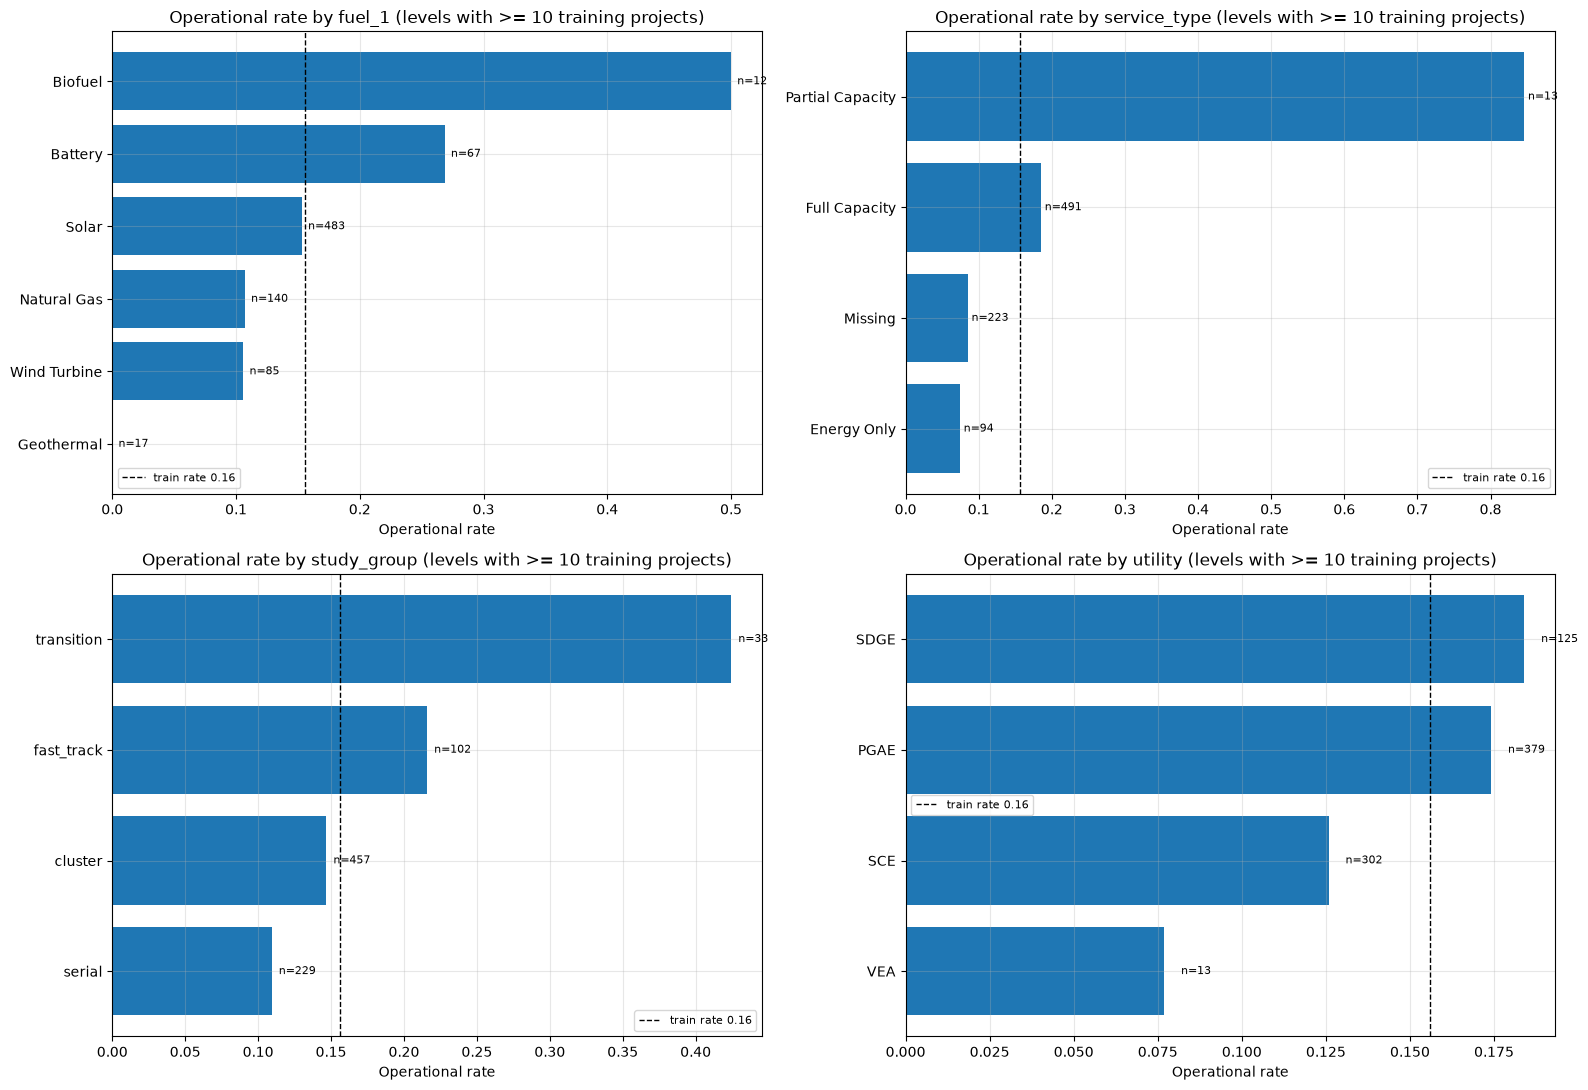

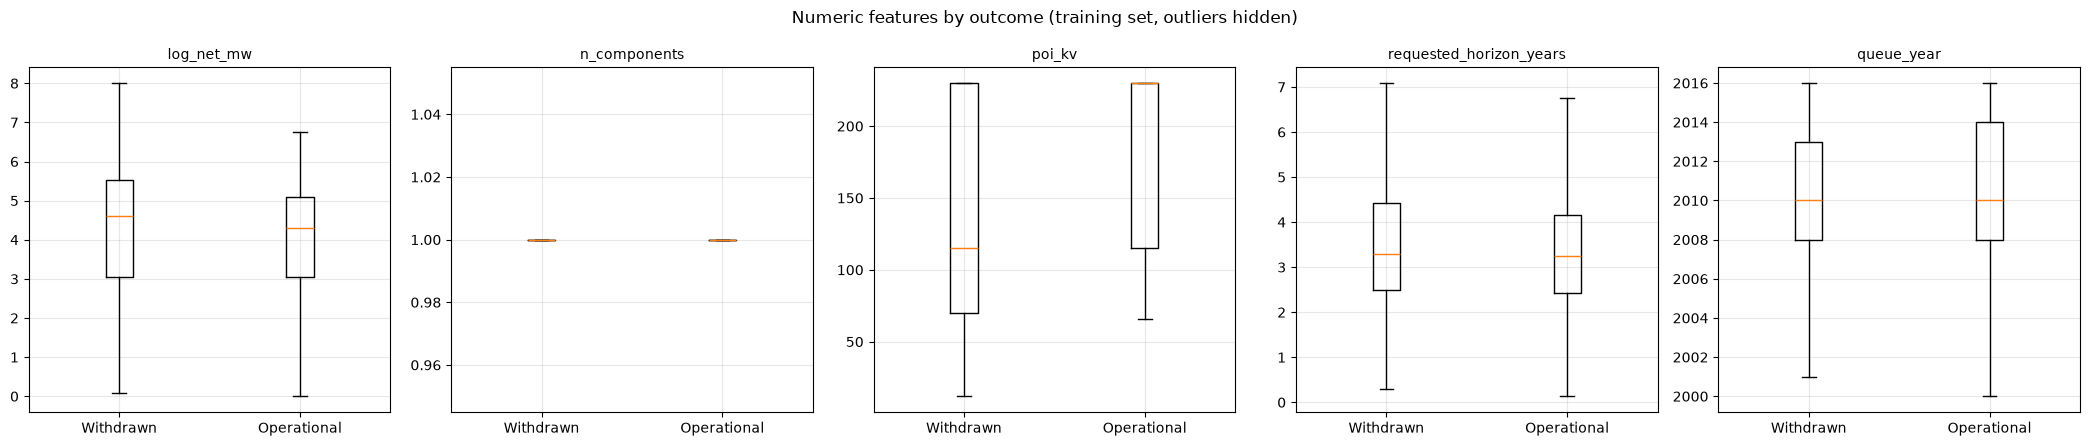

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, col in zip(axes.ravel(), ["fuel_1", "service_type", "study_group", "utility"]):
    grouped = pd.DataFrame({"level": Xa[col], "y": y}).groupby("level")["y"].agg(["mean", "count"])
    grouped = grouped[grouped["count"] >= 10].sort_values("mean")
    ax.barh(grouped.index.astype(str), grouped["mean"], color="tab:blue")
    for i, (rate, n) in enumerate(zip(grouped["mean"], grouped["count"])):
        ax.text(rate + 0.005, i, f"n={n}", va="center", fontsize=8)
    ax.axvline(y.mean(), color="k", ls="--", lw=1, label=f"train rate {y.mean():.2f}")
    ax.set(title=f"Operational rate by {col} (levels with >= 10 training projects)", xlabel="Operational rate")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(num_cols), figsize=(4.2 * len(num_cols), 4.5))
for ax, col in zip(np.atleast_1d(axes), num_cols):
    data = [Xa.loc[y == 0, col].dropna(), Xa.loc[y == 1, col].dropna()]
    ax.boxplot(data, tick_labels=["Withdrawn", "Operational"], showfliers=False)
    ax.set_title(col, fontsize=10)
fig.suptitle("Numeric features by outcome (training set, outliers hidden)")
fig.tight_layout()
plt.show()

**Interpretation.** The bar charts show the same pattern visually. **Battery** (27%, 67 projects) and the small **biofuel**
group stand out among fuels, while solar sits at the average and wind and gas sit below it. **Partial Capacity** dominates
the service types, and **Energy Only** and **Missing** sit well below average. Among utilities, SDG&E and PG&E territories sit
above average and SCE below it, but the differences are modest.

The box plots show **heavy overlap** for every numeric feature. Point-of-interconnection voltage separates best, with
operational projects concentrated at 115-230 kV. No single variable separates the outcomes, so the model can only be a
probabilistic risk signal, not a sorter.

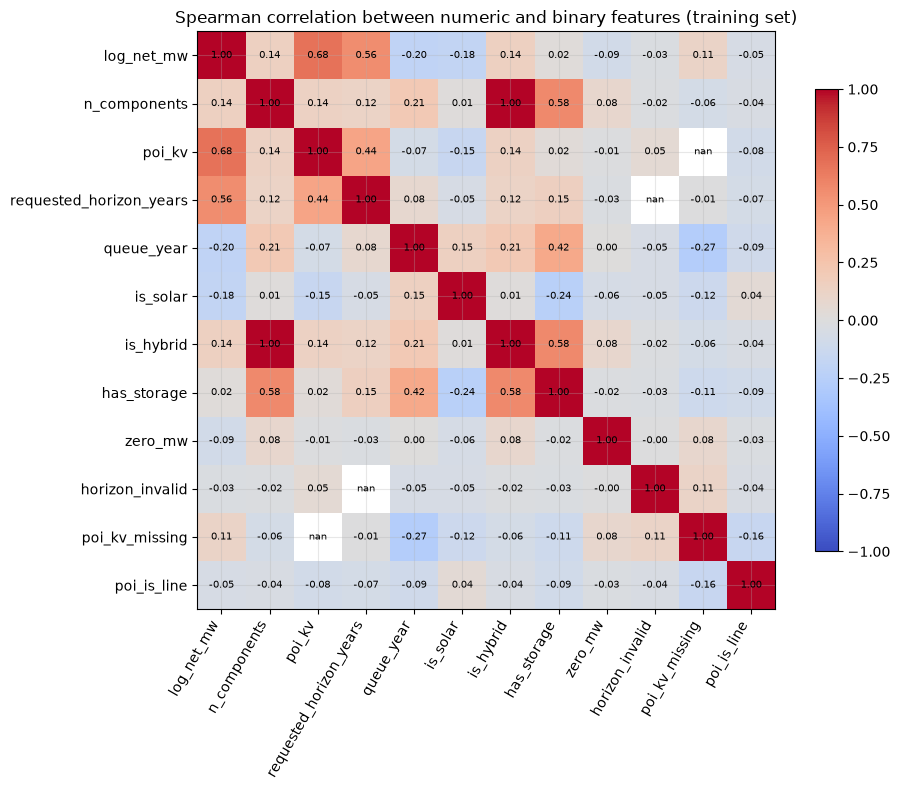

Feature pairs with |Spearman rho| > 0.7:


,,spearman_rho
n_components,is_hybrid,1.000


Dropped features so far: ['days_ir_to_queue', 'is_hybrid']


In [13]:
corr = Xa[num_cols + bin_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for (i, j), value in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation between numeric and binary features (training set)")
fig.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Feature pairs with |Spearman rho| > 0.7:")
display(pairs[pairs.abs() > 0.7].to_frame("spearman_rho"))

# Decision: a feature that duplicates another (|rho| > 0.95) adds no information and splits Logistic
# Regression coefficients between two columns, so the less granular one is dropped.
if abs(corr.loc["n_components", "is_hybrid"]) > 0.95:
    DROP_FEATURES["is_hybrid"] = ("Duplicates n_components (Spearman rho = 1.0 on train): a hybrid is exactly a "
                                  "project with more than one component; n_components keeps the finer detail.")
    bin_cols = [c for c in bin_cols if c not in DROP_FEATURES]
print("Dropped features so far:", list(DROP_FEATURES))

**Interpretation.** One pair is an exact duplicate: `n_components` and `is_hybrid` (Spearman rho = 1.0). A hybrid project is,
by construction, a project with more than one component. All other pairs fall below |rho| = 0.7, so the remaining features
carry distinct information.

**Decision: drop `is_hybrid`.** It adds nothing beyond `n_components`, which also distinguishes 2 versus 3 components. Keeping
both would split one effect across two Logistic Regression coefficients and make the odds ratios harder to read.

## 8. Outliers and transformations

**Purpose.** Decide how to handle extreme values without deleting projects.

**Why it matters.** Very large requests (1,000+ MW) and long requested horizons are real projects, not errors. Removing them
would bias the data, but leaving them raw lets a few values dominate Logistic Regression coefficients.

**Choices (all fit on training data only, inside the model pipelines).**
* `log_net_mw`: a log transform, already applied in feature engineering, because MW is strongly right-skewed.
* Median imputation for missing numeric values.
* **Quantile clipping** at the 1st and 99th training percentiles (`cd.QuantileClipper`): values beyond the bounds are set to
  the bound. The same bounds are reused for test, validation, and new projects.
* **Standard scaling** for Logistic Regression only. Tree models do not need it.
* **One-hot encoding** of categories, pooling categories with fewer than 10 training projects into an "infrequent" bucket.
  CatBoost instead uses its own ordered target statistics, which handle categories natively.

**Key term.** *IQR outlier*: a value more than 1.5 interquartile ranges beyond the 25th or 75th percentile. It is reported as a
description only, and nothing is removed.

,feature,skew,iqr_outliers,min,max,clip_lower,clip_upper,test_values_clipped
0,log_net_mw,-0.257,0,0.000,8.007,0.489,7.000,8
1,n_components,3.613,59,1.000,3.000,1.000,2.000,1
2,poi_kv,1.437,44,12.000,500.000,60.000,500.000,1
3,requested_horizon_years,0.891,12,0.134,13.582,0.671,7.478,10
4,queue_year,-0.115,5,2000.000,2016.000,2003.000,2016.000,6


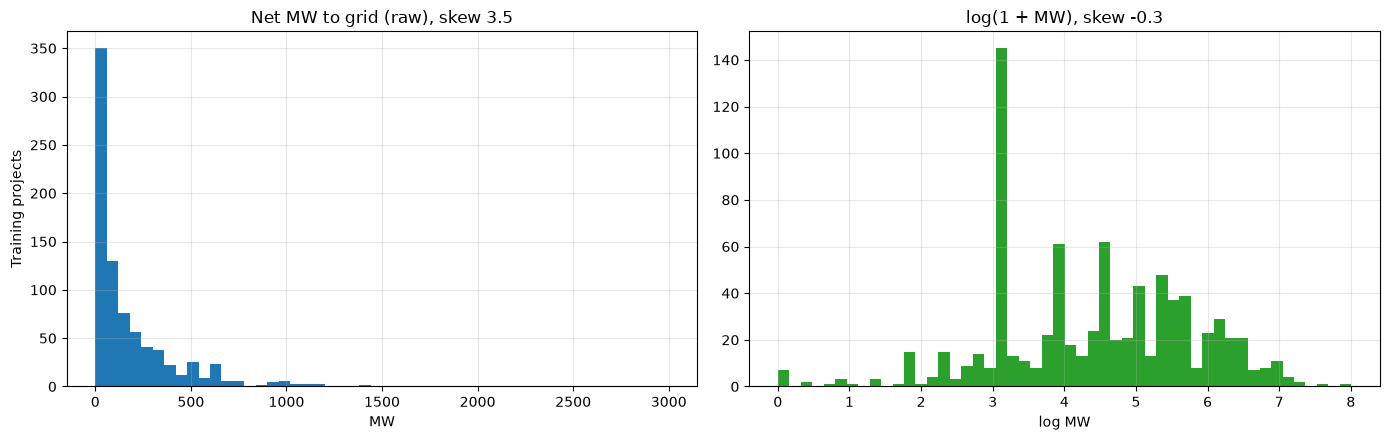

In [14]:
rows = []
for col in num_cols:
    values = Xa[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    rows.append({"feature": col, "skew": values.skew(),
                 "iqr_outliers": int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()),
                 "min": values.min(), "max": values.max()})
outliers = pd.DataFrame(rows)

# Clipping bounds learned on train (after median imputation), then applied to the test set.
imputed_train = Xa[num_cols].fillna(Xa[num_cols].median())
clipper = cd.QuantileClipper().fit(imputed_train)
features_test_all = cd.engineer_features(test_df)
imputed_test = features_test_all[num_cols].fillna(Xa[num_cols].median())
outliers["clip_lower"] = clipper.lower_bounds_
outliers["clip_upper"] = clipper.upper_bounds_
outliers["test_values_clipped"] = ((imputed_test < clipper.lower_bounds_) | (imputed_test > clipper.upper_bounds_)).sum().values
display(outliers)

raw_mw = train_df["net_mw_to_grid"].fillna(train_df[["mw_1", "mw_2", "mw_3"]].fillna(0).sum(axis=1))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(raw_mw, bins=50)
axes[0].set(title=f"Net MW to grid (raw), skew {raw_mw.skew():.1f}", xlabel="MW", ylabel="Training projects")
axes[1].hist(Xa["log_net_mw"], bins=50, color="tab:green")
axes[1].set(title=f"log(1 + MW), skew {Xa['log_net_mw'].skew():.1f}", xlabel="log MW")
fig.tight_layout()
plt.show()

**Interpretation.**
* **Capacity:** raw MW is strongly right-skewed (see the left histogram); after the log transform the skew is -0.26, roughly
  symmetric.
* **IQR "outliers" are mostly not errors.** `n_components` flags 59 projects only because 75% of projects have a single
  component, so every multi-component project is "unusual." `poi_kv` flags 44 projects, which are legitimate 500 kV bulk
  connections. `requested_horizon_years` flags 12 long requests.
* **Clipping bounds learned on train:** requested horizon is capped at 7.5 years (10 test values affected) and `log_net_mw`
  at 7.0, about 1,100 MW (8 test values). `n_components` is capped at 2, which merges the few 3-component projects into the
  2-component group. The `queue_year` row is informational, since that feature is evaluated next.

No projects were removed. Clipping only limits how hard an extreme value can push a linear model.

## 9. `queue_year` ablation

**Purpose.** Decide whether the calendar year of queue entry should be a feature.

**Why it matters.** `queue_year` is an *era proxy*. It bundles tariff reforms, technology cost declines, market conditions, and
any remaining label-maturity effect into one number. It may improve historical accuracy, but it causes two problems for the
agent:
1. Every project the agent scores (Cluster 15, active Cluster 14 projects) is queued **after** the training cutoff, so
   `queue_year` would be outside the training range. Trees would treat it as the last training year; Logistic Regression
   would extrapolate the trend linearly.
2. It is confounded: its effect is not interpretable as anything a developer controls.

**Method.** 5-fold stratified cross-validation (CV) **on the training set only**, with and without `queue_year`, for a linear
model (Logistic Regression) and a tree model (XGBoost) at reasonable default settings. Scoring is PR-AUC (average precision)
and ROC-AUC.

**Decision rule (set before looking at the results).** Keep `queue_year` only if it raises mean CV PR-AUC by at least 0.02
for **both** models. Otherwise drop it, because the extrapolation risk above outweighs a small gain.

**Key terms.** *Cross-validation*: the training set is cut into 5 folds; each fold is scored by a model trained on the other 4.
*PR-AUC (average precision)*: the average precision across all recall levels. Its no-skill value equals the positive rate (about 0.16 here).

In [15]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCALE_POS_WEIGHT = float((y_train_raw == 0).sum() / (y_train_raw == 1).sum())


def make_lr(numeric, binary, categorical, C=1.0):
    # L2-regularized, class-balanced Logistic Regression on scaled, clipped, one-hot features.
    return Pipeline([("prep", cd.build_preprocessor(numeric, binary, categorical, scale=True)),
                     ("model", LogisticRegression(C=C, class_weight="balanced", max_iter=5000))])


def make_xgb(numeric, binary, categorical, **params):
    # Gradient-boosted trees; scale_pos_weight up-weights the minority (operational) class.
    defaults = dict(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.85, colsample_bytree=0.7,
                    scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="logloss", random_state=SEED, n_jobs=4)
    defaults.update(params)
    return Pipeline([("prep", cd.build_preprocessor(numeric, binary, categorical, scale=False)),
                     ("model", XGBClassifier(**defaults))])


rows = []
for with_year in [True, False]:
    numeric = [c for c in num_cols if with_year or c != "queue_year"]
    X_ab = Xa[numeric + bin_cols + cat_cols]
    for name, builder in [("Logistic Regression", make_lr), ("XGBoost", make_xgb)]:
        scores = cross_validate(builder(numeric, bin_cols, cat_cols), X_ab, y, cv=CV,
                                scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
        rows.append({"model": name, "queue_year": "included" if with_year else "excluded",
                     "cv_pr_auc_mean": scores["test_pr_auc"].mean(), "cv_pr_auc_std": scores["test_pr_auc"].std(),
                     "cv_roc_auc_mean": scores["test_roc_auc"].mean()})
ablation = pd.DataFrame(rows)
display(ablation)

gain = (ablation[ablation["queue_year"] == "included"].set_index("model")["cv_pr_auc_mean"]
        - ablation[ablation["queue_year"] == "excluded"].set_index("model")["cv_pr_auc_mean"])
print("PR-AUC gain from including queue_year:", gain.round(3).to_dict())
USE_QUEUE_YEAR = bool((gain >= 0.02).all())
print("Decision: queue_year", "INCLUDED" if USE_QUEUE_YEAR else "EXCLUDED", "in the main model.")
if not USE_QUEUE_YEAR:
    DROP_FEATURES["queue_year"] = ("Era proxy that every scored project would extrapolate beyond; the ablation "
                                   "gain was below the pre-set 0.02 PR-AUC threshold for at least one model.")

,model,queue_year,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean
0,Logistic Regression,included,0.420,0.106,0.735
1,XGBoost,included,0.543,0.093,0.816
2,Logistic Regression,excluded,0.403,0.109,0.721
3,XGBoost,excluded,0.507,0.109,0.794


PR-AUC gain from including queue_year: {'Logistic Regression': 0.016, 'XGBoost': 0.036}
Decision: queue_year EXCLUDED in the main model.


**Interpretation.** Including `queue_year` raises cross-validated PR-AUC by **0.016 for Logistic Regression** and **0.036 for
XGBoost**. Both gains are small relative to the fold-to-fold standard deviation (about 0.10). Logistic Regression misses the
pre-set 0.02 bar, so by the rule fixed above, **`queue_year` is excluded**.

This trades a little historical accuracy for a model that does not extrapolate a calendar trend onto 2017-2026 projects.
`study_group` and `service_type = Missing` still carry some era information (serial study processes and unrecorded service
types belong to the older era); Section 14 examines what that means for new projects.

## 10. Models: tuning, calibration, and out-of-fold predictions

**Purpose.** Train five models on the same features and training set and produce honest probability estimates for each.

| Model | Why it is included |
|---|---|
| Dummy (base rate) | Predicts the training operational rate for everyone. Any useful model must beat it. |
| Logistic Regression | Linear, L2-regularized, class-balanced. Transparent coefficients (odds ratios); a strong baseline on small data. |
| Random Forest | Averages many decision trees; captures interactions and is robust to noise. |
| XGBoost | Gradient-boosted trees; usually the strongest tabular learner; `scale_pos_weight` handles imbalance. |
| CatBoost | Gradient boosting with native categorical handling, useful for high-cardinality fields like county and utility. |

**Method.**
1. **Tuning**: `RandomizedSearchCV` with 5-fold stratified CV on the training set, scored by PR-AUC. PR-AUC was chosen because
   the positive class is small (about 16%) and we care most about ranking the projects likely to reach operation.
2. **Calibration**: class weighting (used to help the models learn the minority class) distorts probabilities, so each tuned
   model is wrapped in `CalibratedClassifierCV` with **sigmoid (Platt) scaling** and 5 internal folds. Sigmoid is preferred
   over isotonic regression because there are only about 128 operational training projects; isotonic regression needs more
   data and tends to overfit.
3. **Out-of-fold (OOF) predictions**: `cross_val_predict` gives every training project a probability from a calibrated model
   that never saw it. These OOF predictions are used for model comparison and threshold selection, so the test set is used
   only once, in Section 12.

**Caveat (explicit).** Hyperparameters were tuned on the full training set before computing OOF predictions, so OOF scores
are slightly optimistic. Fully nested CV would remove this but costs about 5 times more compute. The single test-set
evaluation in Section 12 is the unbiased check.

**Key terms.** *Hyperparameter*: a setting chosen before training (e.g., tree depth). *Brier score*: mean squared error of
probabilities (lower is better; predicting the base rate for everyone scores about 0.13 here).

In [16]:
NUMERIC = [c for c in cd.NUMERIC_FEATURES if c not in DROP_FEATURES]
BINARY = [c for c in cd.BINARY_FEATURES if c not in DROP_FEATURES]
CATEGORICAL = [c for c in cd.CATEGORICAL_FEATURES if c not in DROP_FEATURES]
FEATURES = NUMERIC + BINARY + CATEGORICAL
print(f"{len(FEATURES)} model features:", FEATURES)
print("Dropped:", list(DROP_FEATURES))

X_train = cd.engineer_features(train_df)[FEATURES]
X_test = cd.engineer_features(test_df)[FEATURES]
y_train = train_df[cd.TARGET].to_numpy()
y_test = test_df[cd.TARGET].to_numpy()
solar_train = train_df["is_solar"].to_numpy()
solar_test = test_df["is_solar"].to_numpy()
cd.assert_no_leakage(X_train)

MODEL_SPECS = {
    "Logistic Regression": (
        make_lr(NUMERIC, BINARY, CATEGORICAL),
        {"model__C": loguniform(1e-3, 10)}, 20),
    "Random Forest": (
        Pipeline([("prep", cd.build_preprocessor(NUMERIC, BINARY, CATEGORICAL, scale=False)),
                  ("model", RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1))]),
        {"model__max_depth": [3, 4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5, 10, 20],
         "model__max_features": ["sqrt", 0.3, 0.5], "model__class_weight": ["balanced", "balanced_subsample", None]}, 20),
    "XGBoost": (
        make_xgb(NUMERIC, BINARY, CATEGORICAL),
        {"model__max_depth": [2, 3, 4, 5], "model__learning_rate": [0.02, 0.05, 0.1],
         "model__n_estimators": [150, 300, 500], "model__min_child_weight": [1, 3, 5, 10],
         "model__subsample": [0.7, 0.85, 1.0], "model__colsample_bytree": [0.5, 0.7, 1.0],
         "model__reg_lambda": [1, 5, 10]}, 25),
    "CatBoost": (
        Pipeline([("model", cd.CatBoostCategoricalClassifier(cat_features=tuple(CATEGORICAL), random_seed=SEED))]),
        {"model__depth": [3, 4, 5, 6], "model__learning_rate": [0.03, 0.05, 0.1],
         "model__iterations": [300, 500], "model__l2_leaf_reg": [1, 3, 5, 10]}, 12),
}

searches, tuned, calibrated, oof, oof_uncal = {}, {}, {}, {}, {}
for name, (estimator, params, n_iter) in MODEL_SPECS.items():
    search = RandomizedSearchCV(estimator, params, n_iter=n_iter, scoring="average_precision", cv=CV,
                                random_state=SEED, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    tuned[name] = search.best_estimator_  # uncalibrated, refit on all training data (used for SHAP and odds ratios)
    calibrated[name] = CalibratedClassifierCV(clone(search.best_estimator_), method="sigmoid", cv=CV)
    oof[name] = cross_val_predict(calibrated[name], X_train, y_train, cv=CV, method="predict_proba")[:, 1]
    oof_uncal[name] = cross_val_predict(clone(search.best_estimator_), X_train, y_train, cv=CV, method="predict_proba")[:, 1]
    calibrated[name].fit(X_train, y_train)
    print(f"{name:20s} best CV PR-AUC {search.best_score_:.3f}  params {search.best_params_}")

# Baseline: predicts the training base rate for everyone (no calibration needed).
dummy = DummyClassifier(strategy="prior")
oof["Dummy (base rate)"] = cross_val_predict(dummy, X_train, y_train, cv=CV, method="predict_proba")[:, 1]
calibrated["Dummy (base rate)"] = dummy.fit(X_train, y_train)
MODEL_NAMES = ["Dummy (base rate)"] + list(MODEL_SPECS)

17 model features: ['log_net_mw', 'n_components', 'poi_kv', 'requested_horizon_years', 'is_solar', 'has_storage', 'zero_mw', 'horizon_invalid', 'poi_kv_missing', 'poi_is_line', 'fuel_1', 'type_1', 'service_type', 'utility', 'state', 'county', 'study_group']
Dropped: ['days_ir_to_queue', 'is_hybrid', 'queue_year']


Logistic Regression  best CV PR-AUC 0.414  params {'model__C': np.float64(6.351221010640703)}


Random Forest        best CV PR-AUC 0.576  params {'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': 8, 'model__class_weight': None}


XGBoost              best CV PR-AUC 0.531  params {'model__subsample': 0.85, 'model__reg_lambda': 5, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.5}


CatBoost             best CV PR-AUC 0.579  params {'model__learning_rate': 0.05, 'model__l2_leaf_reg': 1, 'model__iterations': 300, 'model__depth': 6}


**Interpretation.** The final feature set has **17 features**: 4 numeric, 6 binary, and 7 categorical. Tuning chose:
* **Logistic Regression:** weak regularization (C = 6.4).
* **Random Forest:** fairly deep trees (max depth 8, 30% of features per split) without class weighting.
* **XGBoost:** depth 5, 300 trees at learning rate 0.05, half the features per tree.
* **CatBoost:** depth 6, 300 iterations.

Best cross-validated PR-AUC during tuning was 0.41 (Logistic Regression), 0.53 (XGBoost), 0.58 (Random Forest), and 0.58
(CatBoost). These search scores come from uncalibrated models and the best of many tries, so they are optimistic. The
calibrated out-of-fold scores below are the ones used for comparison.

Out-of-fold (training set) metrics; calibrated models unless noted


,base_rate,roc_auc,pr_auc,brier,log_loss,solar_pr_auc,solar_roc_auc,mean_predicted_prob,cv_pr_auc_fold_std,brier_before_calibration,mean_prob_before_calibration
model,,,,,,,,,,,
Dummy (base rate),0.156,0.494,0.154,0.132,0.433,0.145,0.476,0.156,NaN,NaN,NaN
Logistic Regression,0.156,0.721,0.400,0.116,0.387,0.534,0.768,0.157,0.100,0.186,0.372
Random Forest,0.156,0.799,0.522,0.100,0.339,0.567,0.814,0.157,0.132,0.100,0.151
XGBoost,0.156,0.790,0.505,0.102,0.342,0.616,0.821,0.154,0.080,0.118,0.243
CatBoost,0.156,0.795,0.529,0.100,0.340,0.612,0.825,0.155,0.112,0.102,0.197


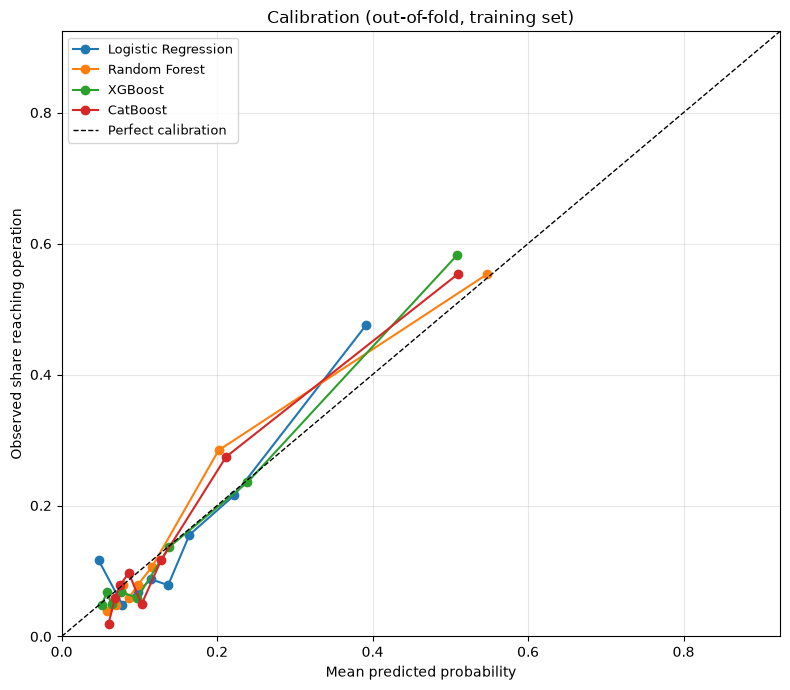

In [17]:
rows = []
for name in MODEL_NAMES:
    row = {"model": name, **ce.probability_metrics(y_train, oof[name])}
    row["solar_pr_auc"] = average_precision_score(y_train[solar_train], oof[name][solar_train])
    row["solar_roc_auc"] = roc_auc_score(y_train[solar_train], oof[name][solar_train])
    if name in searches:
        s = searches[name]
        row["cv_pr_auc_fold_std"] = s.cv_results_["std_test_score"][s.best_index_]
        row["brier_before_calibration"] = ce.probability_metrics(y_train, oof_uncal[name])["brier"]
        row["mean_prob_before_calibration"] = oof_uncal[name].mean()
    row["mean_predicted_prob"] = oof[name].mean()
    rows.append(row)
oof_table = pd.DataFrame(rows).set_index("model")
print("Out-of-fold (training set) metrics; calibrated models unless noted")
display(oof_table)

fig = ce.plot_calibration({n: (y_train, oof[n]) for n in MODEL_SPECS}, n_bins=8, title_suffix=" (out-of-fold, training set)")
plt.show()

**Interpretation (out-of-fold, training set).**
* **Every model beats the dummy baseline**, whose PR-AUC is 0.154 and Brier score 0.132.
* **Tree models score about 0.51-0.53 PR-AUC and 0.79-0.80 ROC-AUC. Logistic Regression scores 0.40 and 0.72.** The gap means
  that interactions and non-linear effects matter, for example how storage, service type, and voltage combine.
* **Calibration was necessary.** Before calibration, the class-balanced Logistic Regression predicted an average of 0.37 when the
  true rate is 0.156, and its Brier score (0.186) was *worse than the dummy*. Sigmoid calibration brought it to 0.116. XGBoost
  improved from 0.118 to 0.102. After calibration every model's mean prediction matches the base rate (about 0.155).
* **The reliability plot** tracks the diagonal reasonably well up to about 0.55, with slight under-prediction around 0.2. The
  probabilities can be read roughly literally for mature-era projects.
* **Fold-to-fold standard deviation is 0.08-0.13**, larger than the differences among the three tree models, so they are
  statistically indistinguishable.
* **Solar OOF PR-AUC is 0.57-0.62** for the tree models against a base rate of about 0.15.

**Decision: model-selection rule (fixed before looking at the test set).** Selection uses only out-of-fold training metrics.
1. Shortlist every model whose OOF PR-AUC is within **0.01** of the best model's (differences smaller than that are well inside
   fold-to-fold noise; see `cv_pr_auc_fold_std`).
2. If Logistic Regression is on the shortlist, choose it: it is the most transparent, the easiest to explain in an agent
   report, and the most stable on small data.
3. Otherwise choose the shortlisted model with the lowest OOF Brier score (best probability quality).

The selected model is used in Sections 11-15. Section 16 reviews the choice in light of the test results.

In [18]:
candidates = oof_table.drop(index="Dummy (base rate)")
shortlist = candidates[candidates["pr_auc"] >= candidates["pr_auc"].max() - 0.01]
if "Logistic Regression" in shortlist.index:
    FINAL_MODEL = "Logistic Regression"
else:
    FINAL_MODEL = shortlist["brier"].idxmin()
TREE_MODELS = ["Random Forest", "XGBoost", "CatBoost"]
BEST_TREE = candidates.loc[TREE_MODELS, "pr_auc"].idxmax()
print("Shortlist (OOF PR-AUC within 0.01 of best):", list(shortlist.index))
print("Selected model:", FINAL_MODEL, "| best tree model (for SHAP):", BEST_TREE)

Shortlist (OOF PR-AUC within 0.01 of best): ['Random Forest', 'CatBoost']
Selected model: Random Forest | best tree model (for SHAP): CatBoost


**Interpretation.** CatBoost has the best OOF PR-AUC (0.529), and Random Forest is within 0.01 (0.522). Logistic Regression
(0.400) is far off the shortlist, so the rule falls through to the lowest OOF Brier score. Random Forest and CatBoost are tied
at 0.100 to three decimals, and **Random Forest** wins by a hair.

In practice these two models are interchangeable on this evidence. Random Forest has a practical edge for deployment: it needs
only scikit-learn at scoring time. CatBoost, the best tree model by PR-AUC, is used for the SHAP analysis in Section 15.

## 11. Threshold optimization on out-of-fold predictions

**Purpose.** Turn probabilities into yes/no flags only where a decision needs one, and choose thresholds with the training set's
OOF predictions so the test set stays unbiased.

**Why it matters.** The default threshold of 0.5 is arbitrary. With a calibrated model and a 16% base rate, very few
projects score above 0.5, so a 0.5 threshold would flag almost nothing. The right threshold depends on the user's decision.

**Criteria compared.**
* **Youden's J** = true positive rate - false positive rate. This is the formal version of "maximize true positives while
  minimizing false positives," with both rates weighted equally.
* **Max F1**: best balance of precision and recall.
* **Max F0.5**: weights precision twice as much as recall. It fits an investor who wants the flagged list to be reliable.
* **Cost ratios** (FP:FN = 1:1, 2:1, 3:1, 5:1): minimize expected cost when backing a project that later withdraws (false
  positive) costs r times as much as passing on one that would have succeeded (false negative).
* **Recall 90%**: the highest threshold that still catches 90% of operational projects. Projects below it rarely succeed, so it
  defines the "lower realization likelihood" tier.

**Key terms.** *Precision*: of flagged projects, the share that reached operation. *Recall*: of projects that reached
operation, the share that were flagged.

OOF-optimal thresholds by criterion and model


,Logistic Regression,Random Forest,XGBoost,CatBoost
criterion,,,,
youden_j,0.210,0.150,0.150,0.150
max_f1,0.210,0.150,0.340,0.180
max_f0_5,0.280,0.560,0.430,0.450
cost_FP:FN=1:1,0.440,0.560,0.430,0.450
cost_FP:FN=2:1,0.650,0.560,0.630,0.500
cost_FP:FN=3:1,0.730,0.740,0.630,0.500
cost_FP:FN=5:1,0.730,0.740,0.680,0.780
recall_90,0.060,0.070,0.060,0.070


Selected model (Random Forest): OOF performance at each criterion's threshold


,criterion,threshold,tp,fp,fn,precision,recall,fpr,f1,f0_5,youden_j,flagged_share
0,youden_j,0.150,86.000,106.000,42.000,0.448,0.672,0.153,0.537,0.480,0.519,0.234
1,max_f1,0.150,86.000,106.000,42.000,0.448,0.672,0.153,0.537,0.480,0.519,0.234
2,max_f0_5,0.560,35.000,9.000,93.000,0.795,0.273,0.013,0.407,0.576,0.260,0.054
3,cost_FP:FN=1:1,0.560,35.000,9.000,93.000,0.795,0.273,0.013,0.407,0.576,0.260,0.054
4,cost_FP:FN=2:1,0.560,35.000,9.000,93.000,0.795,0.273,0.013,0.407,0.576,0.260,0.054
5,cost_FP:FN=3:1,0.740,18.000,3.000,110.000,0.857,0.141,0.004,0.242,0.425,0.136,0.026
6,cost_FP:FN=5:1,0.740,18.000,3.000,110.000,0.857,0.141,0.004,0.242,0.425,0.136,0.026
7,recall_90,0.070,120.000,548.000,8.000,0.180,0.938,0.791,0.302,0.214,0.147,0.814


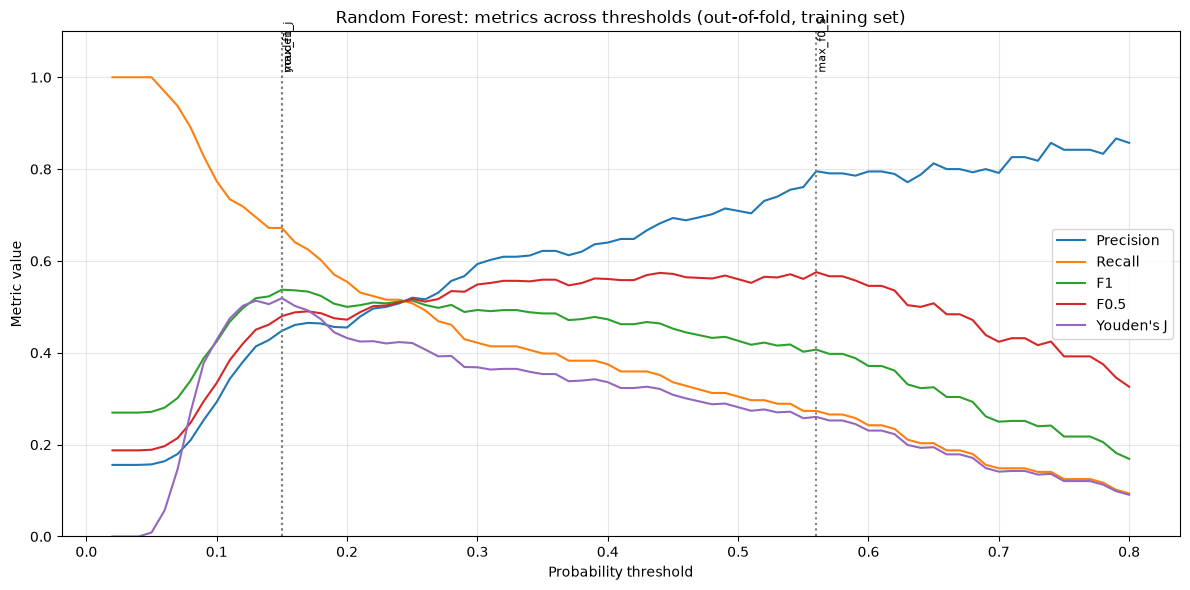

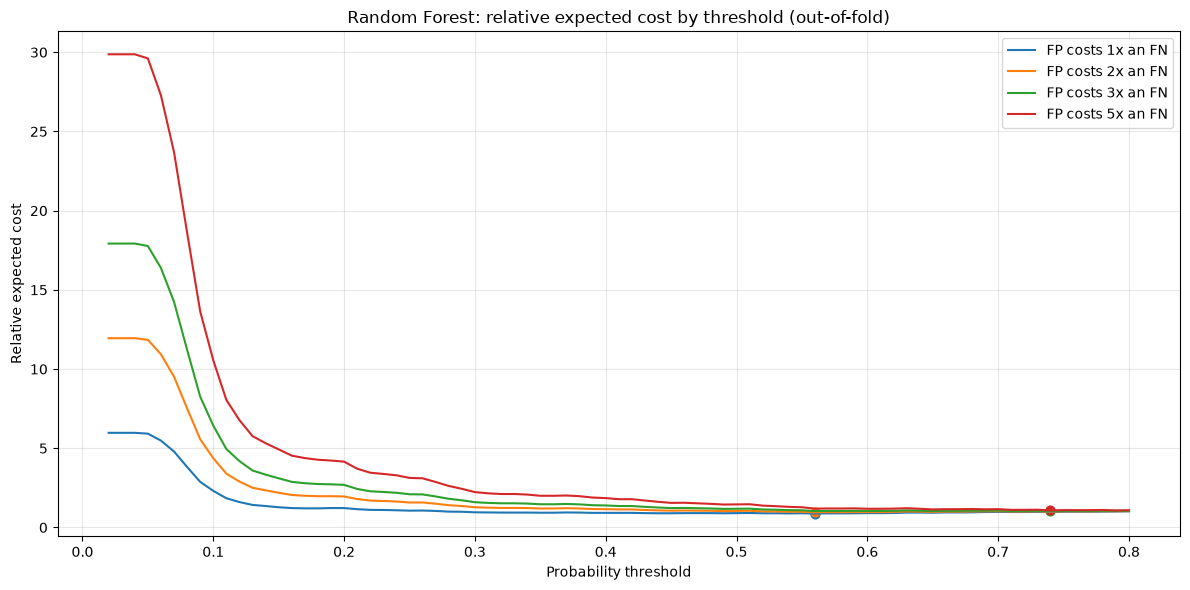

Risk tiers: lower < 0.07 <= moderate < 0.56 <= higher


In [19]:
sweeps = {name: ce.threshold_sweep(y_train, oof[name]) for name in MODEL_SPECS}
chosen = {name: ce.choose_thresholds(sweeps[name]) for name in MODEL_SPECS}

threshold_table = pd.DataFrame({name: chosen[name].set_index("criterion")["threshold"] for name in MODEL_SPECS})
print("OOF-optimal thresholds by criterion and model")
display(threshold_table)

print(f"Selected model ({FINAL_MODEL}): OOF performance at each criterion's threshold")
display(chosen[FINAL_MODEL][["criterion", "threshold", "tp", "fp", "fn", "precision", "recall", "fpr", "f1",
                             "f0_5", "youden_j", "flagged_share"]])

fig = ce.plot_threshold_tradeoffs(sweeps[FINAL_MODEL], chosen[FINAL_MODEL],
                                  f"{FINAL_MODEL}: metrics across thresholds (out-of-fold, training set)")
plt.show()
fig = ce.plot_cost_curves(sweeps[FINAL_MODEL], title=f"{FINAL_MODEL}: relative expected cost by threshold (out-of-fold)")
plt.show()

final_thresholds = chosen[FINAL_MODEL].set_index("criterion")["threshold"].to_dict()
TIER_LOW = float(final_thresholds["recall_90"])
TIER_HIGH = float(final_thresholds["max_f0_5"])
assert TIER_HIGH > TIER_LOW, "Tier thresholds overlap; revisit the tier rule."
print(f"Risk tiers: lower < {TIER_LOW:.2f} <= moderate < {TIER_HIGH:.2f} <= higher")

**Interpretation (Random Forest, out-of-fold).**
* **Youden's J and max F1 both choose 0.15.** That flags 23% of projects with 45% precision and 67% recall.
* **Max F0.5 and the 1:1 and 2:1 cost ratios all choose 0.56.** Only 5.4% of projects are flagged, with 80% precision but 27%
  recall. With a 16% base rate, minimizing the plain count of errors (1:1) favors flagging very few projects.
* **3:1 and 5:1 cost ratios choose 0.74**: 2.6% flagged, 86% precision, 14% recall.
* **Recall 90% gives 0.07**: 94% of operational projects are caught, but 81% of all projects are flagged.

Optimal thresholds differ a lot *between models* (max-F1 is 0.15 for Random Forest and 0.34 for XGBoost) because each model
spreads its probabilities differently. A threshold belongs to its model and is saved with it.

**Risk tiers** (stored in the metadata): **lower** below 0.07, **moderate** from 0.07 to 0.56, **higher** at 0.56 and above.

## 12. Test-set evaluation (all technologies and solar)

**Purpose.** Score every model **once** on the 30% test set it has never seen, using thresholds fixed in Section 11.

**Why it matters.** This is the honest estimate of performance on new mature-cohort projects. Results are shown for all
technologies (the population the model was trained on) and for solar, the agent's main use case. **Solar results are
directional**: the solar test set has only about 37 operational projects, so its metrics have wide uncertainty.

**What is reported.**
* Ranking: ROC-AUC and PR-AUC, with curves.
* Probability quality: Brier score, log loss, and a calibration curve.
* Decisions at each model's OOF max-F1 threshold: accuracy, precision, recall, F1, balanced accuracy, MCC, and confusion
  matrices.
* For the selected model: top-decile precision and lift, behavior at the default 0.5 threshold, and bootstrap 95% confidence
  intervals.

**Key terms.** *Balanced accuracy*: average of recall on each class (0.5 = chance). *MCC (Matthews correlation coefficient)*:
correlation between predictions and outcomes that stays honest under imbalance (0 = chance, 1 = perfect). *Lift*: precision
among the top-scored projects divided by the base rate. *Bootstrap CI*: the range a metric covers when the test projects
are resampled 1,000 times.

In [20]:
test_prob = {name: calibrated[name].predict_proba(X_test)[:, 1] for name in MODEL_NAMES}
max_f1_threshold = {name: float(threshold_table.loc["max_f1", name]) for name in MODEL_SPECS}
max_f1_threshold["Dummy (base rate)"] = float(oof["Dummy (base rate)"].mean())


def evaluation_table(mask):
    rows = []
    for name in MODEL_NAMES:
        row = {"model": name, **ce.probability_metrics(y_test[mask], test_prob[name][mask]),
               "mean_predicted_prob": test_prob[name][mask].mean()}
        row.update({k: v for k, v in ce.classification_metrics(y_test[mask], test_prob[name][mask],
                                                                max_f1_threshold[name]).items()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")


all_mask = np.ones(len(y_test), dtype=bool)
test_all = evaluation_table(all_mask)
test_solar = evaluation_table(solar_test)
print(f"TEST, all technologies (n={len(y_test)}, operational={y_test.sum()}); hard metrics at each model's OOF max-F1 threshold")
display(test_all)
print(f"TEST, solar only (n={solar_test.sum()}, operational={y_test[solar_test].sum()}); directional")
display(test_solar)

TEST, all technologies (n=412, operational=64); hard metrics at each model's OOF max-F1 threshold


,base_rate,roc_auc,pr_auc,brier,log_loss,mean_predicted_prob,threshold,accuracy,precision,recall,f1,balanced_accuracy,mcc,tp,fp,fn,tn,flagged_share
model,,,,,,,,,,,,,,,,,,
Dummy (base rate),0.155,0.500,0.155,0.131,0.432,0.156,0.156,0.155,0.155,1.000,0.269,0.500,0.000,64,348,0,0,1.000
Logistic Regression,0.155,0.728,0.363,0.119,0.390,0.153,0.210,0.806,0.371,0.359,0.365,0.624,0.251,23,39,41,309,0.150
Random Forest,0.155,0.753,0.455,0.113,0.373,0.142,0.150,0.808,0.410,0.531,0.463,0.695,0.353,34,49,30,299,0.201
XGBoost,0.155,0.722,0.408,0.115,0.382,0.142,0.340,0.833,0.444,0.312,0.367,0.620,0.279,20,25,44,323,0.109
CatBoost,0.155,0.741,0.454,0.112,0.373,0.144,0.180,0.818,0.425,0.484,0.453,0.682,0.345,31,42,33,306,0.177


TEST, solar only (n=243, operational=37); directional


,base_rate,roc_auc,pr_auc,brier,log_loss,mean_predicted_prob,threshold,accuracy,precision,recall,f1,balanced_accuracy,mcc,tp,fp,fn,tn,flagged_share
model,,,,,,,,,,,,,,,,,,
Dummy (base rate),0.152,0.500,0.152,0.129,0.427,0.156,0.156,0.152,0.152,1.000,0.264,0.500,0.000,37,206,0,0,1.000
Logistic Regression,0.152,0.809,0.458,0.110,0.365,0.160,0.210,0.835,0.455,0.405,0.429,0.659,0.334,15,18,22,188,0.136
Random Forest,0.152,0.862,0.612,0.095,0.321,0.139,0.150,0.856,0.525,0.568,0.545,0.738,0.461,21,19,16,187,0.165
XGBoost,0.152,0.842,0.568,0.094,0.316,0.146,0.340,0.872,0.615,0.432,0.508,0.692,0.446,16,10,21,196,0.107
CatBoost,0.152,0.829,0.575,0.096,0.323,0.150,0.180,0.864,0.550,0.595,0.571,0.754,0.491,22,18,15,188,0.165


**Interpretation (test set, scored once).**
* **Random Forest: PR-AUC 0.455, ROC-AUC 0.753, Brier 0.113.** The dummy scores 0.155, 0.500, and 0.131. CatBoost is
  essentially tied (0.454, 0.741, 0.112). XGBoost (0.408) and Logistic Regression (0.363) trail.
* Test scores are below the OOF scores (0.52 PR-AUC). That is expected: hyperparameters were tuned on the training folds, and
  64 test positives is a small, noisy sample. The bootstrap intervals below overlap the OOF value.
* **At Random Forest's OOF max-F1 threshold (0.15):** 34 of 64 operational projects are caught (53% recall), 41% of flagged
  projects reached operation, 20% of projects are flagged, MCC is 0.35, and balanced accuracy is 0.70.
* **Accuracy is misleading here.** Random Forest's 0.81 is *below* the 0.845 one would get by calling every project
  "withdrawn." That is why accuracy is not used to choose models.
* **Solar (directional, 37 positives):** Random Forest's PR-AUC is 0.61 and ROC-AUC 0.86, better than all technologies,
  possibly because solar projects are more uniform than the mixed-technology set. With 37 positives this is not conclusive.
* The mean predicted probability (0.142) is slightly below the observed rate (0.155), a mild under-prediction.

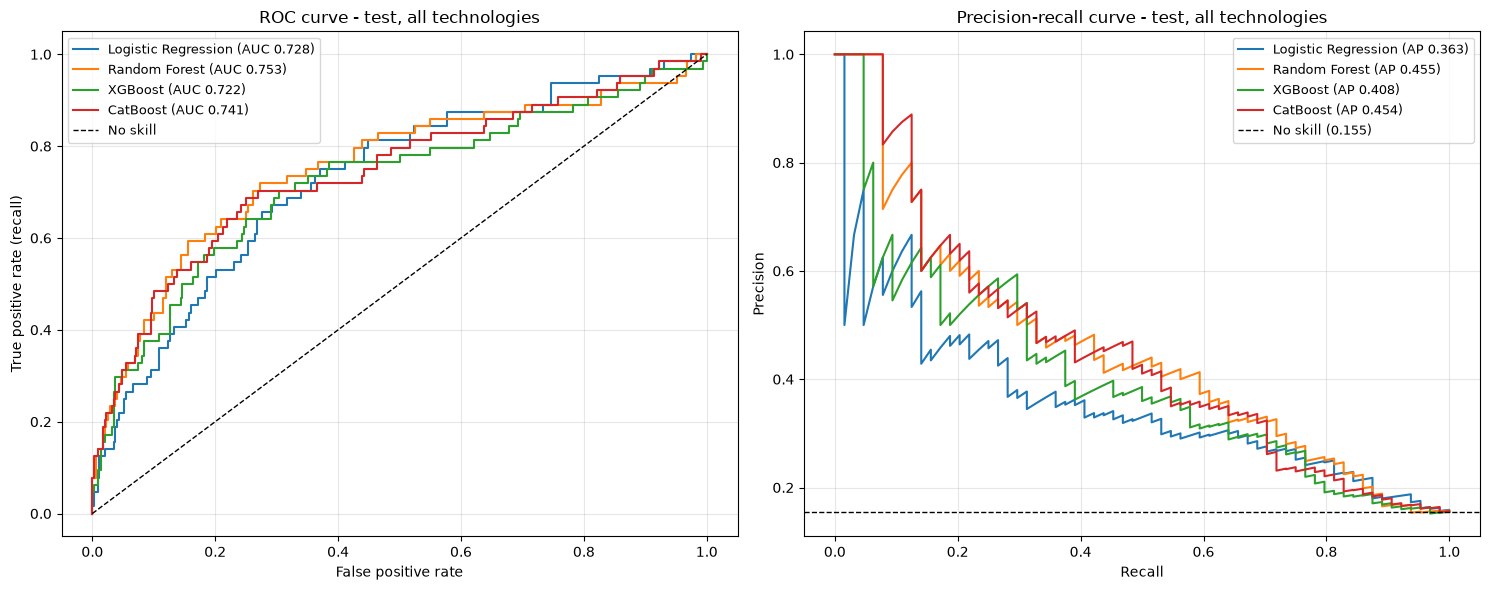

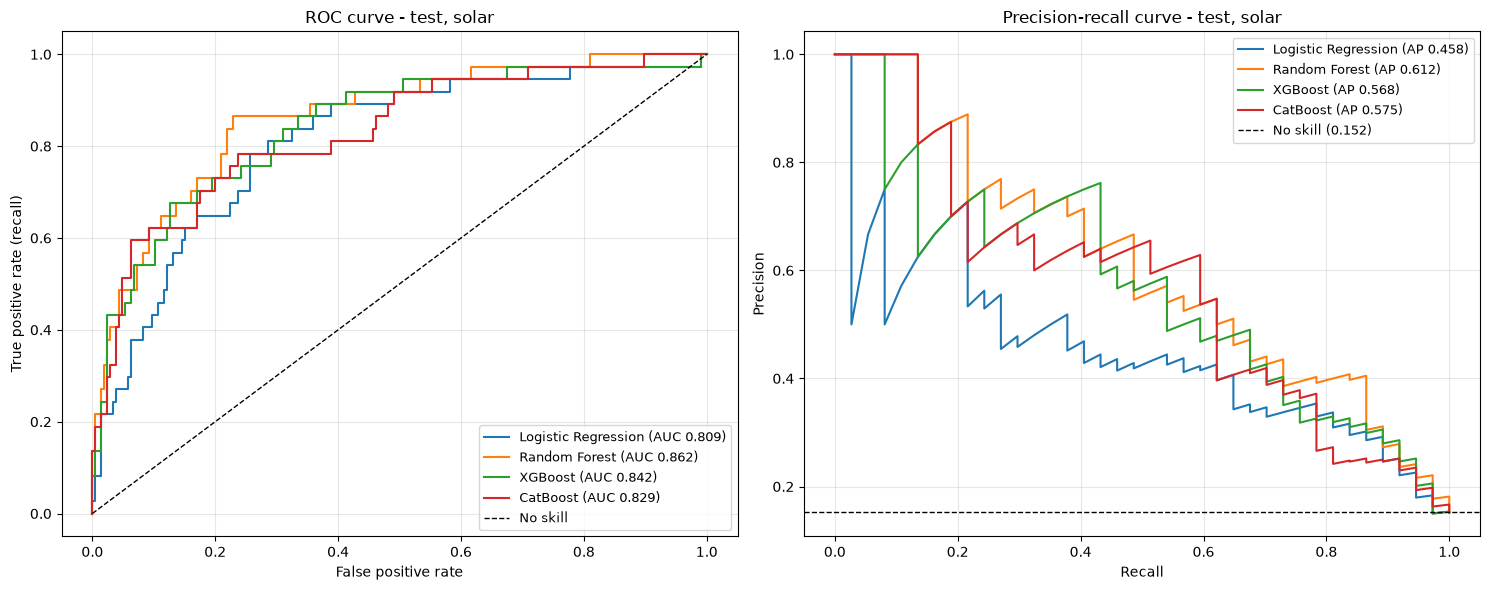

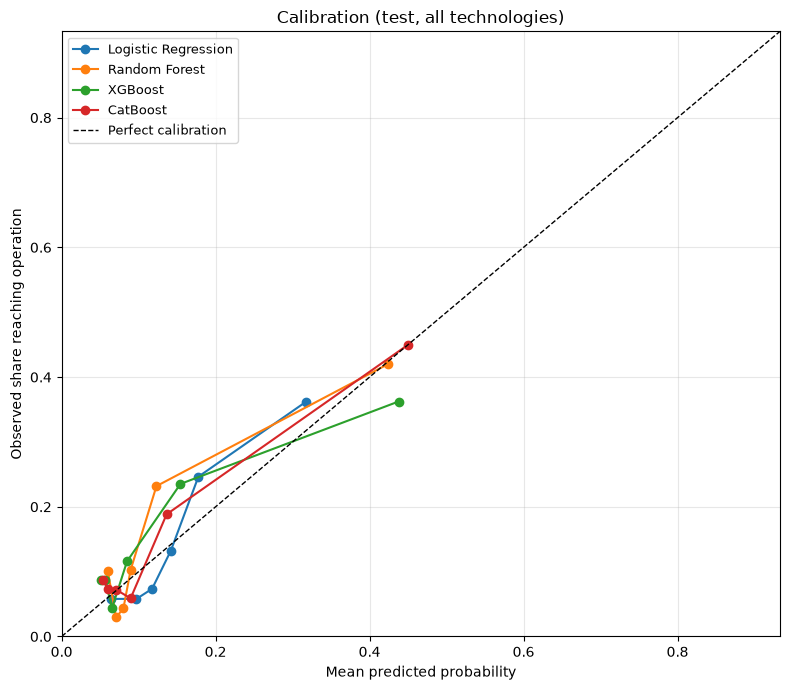

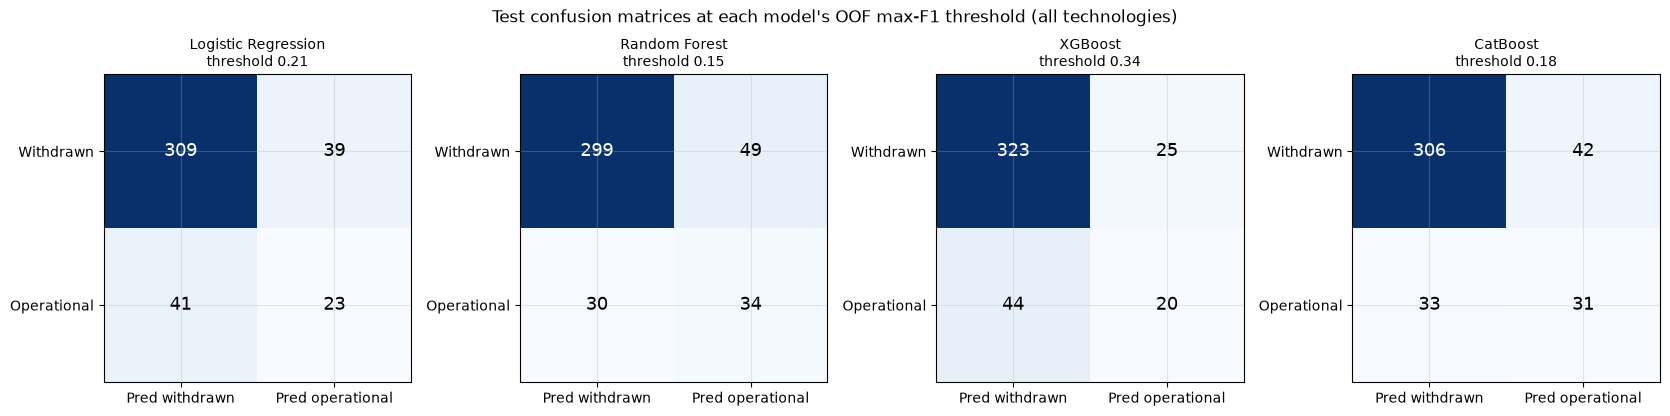

In [21]:
fig = ce.plot_roc_pr({n: (y_test, test_prob[n]) for n in MODEL_SPECS}, title_suffix=" - test, all technologies")
plt.show()
fig = ce.plot_roc_pr({n: (y_test[solar_test], test_prob[n][solar_test]) for n in MODEL_SPECS},
                     title_suffix=" - test, solar")
plt.show()
fig = ce.plot_calibration({n: (y_test, test_prob[n]) for n in MODEL_SPECS}, n_bins=6,
                          title_suffix=" (test, all technologies)")
plt.show()
fig = ce.plot_confusion_matrices({n: (y_test, test_prob[n]) for n in MODEL_SPECS},
                                 {n: max_f1_threshold[n] for n in MODEL_SPECS})
fig.suptitle("Test confusion matrices at each model's OOF max-F1 threshold (all technologies)", y=1.03)
plt.show()

**Interpretation.** The ROC curves of the three tree models overlap almost everywhere, and Logistic Regression sits slightly
below them. On the precision-recall curve, Random Forest and CatBoost hold about 60% precision at 20% recall and about 40% at
50% recall, against a no-skill line of 15.5%. On the test calibration plot, the points stay close to the diagonal; the 0.1-0.2
bins sit slightly above it, which matches the mild under-prediction noted above. The confusion matrices show how thresholds
change the trade: XGBoost's higher threshold (0.34) flags fewer projects, giving fewer false positives and more misses.

In [22]:
p_final = test_prob[FINAL_MODEL]
print(f"{FINAL_MODEL}: top-k precision and lift on the test set")
topk = pd.concat([ce.top_k_metrics(y_test, p_final).assign(subset="all technologies"),
                  ce.top_k_metrics(y_test[solar_test], p_final[solar_test]).assign(subset="solar")])
display(topk)

print(f"{FINAL_MODEL} at the default 0.5 threshold versus the OOF max-F1 threshold ({max_f1_threshold[FINAL_MODEL]:.2f})")
display(pd.DataFrame([ce.classification_metrics(y_test, p_final, 0.5),
                      ce.classification_metrics(y_test, p_final, max_f1_threshold[FINAL_MODEL])]))

boot_all = ce.bootstrap_table(y_test, p_final, max_f1_threshold[FINAL_MODEL]).assign(subset="all technologies")
boot_solar = ce.bootstrap_table(y_test[solar_test], p_final[solar_test],
                                max_f1_threshold[FINAL_MODEL]).assign(subset="solar")
print(f"{FINAL_MODEL}: bootstrap 95% confidence intervals (1,000 resamples of the test set)")
display(pd.concat([boot_all, boot_solar]))

# Bootstrap CI for the PR-AUC gap between the selected model and the dummy baseline.
rng = np.random.default_rng(SEED)
gaps = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if 0 < y_test[idx].sum() < len(idx):
        gaps.append(average_precision_score(y_test[idx], p_final[idx])
                    - average_precision_score(y_test[idx], test_prob["Dummy (base rate)"][idx]))
print(f"PR-AUC gain over the dummy baseline: 95% CI [{np.quantile(gaps, 0.025):.3f}, {np.quantile(gaps, 0.975):.3f}]")

Random Forest: top-k precision and lift on the test set


,top_fraction,projects_selected,operational_in_selection,precision_at_k,recall_at_k,lift,subset
0,0.100,41,21,0.512,0.328,3.297,all technologies
1,0.200,82,34,0.415,0.531,2.669,all technologies
2,0.300,124,41,0.331,0.641,2.129,all technologies
0,0.100,24,15,0.625,0.405,4.105,solar
1,0.200,49,24,0.490,0.649,3.217,solar
2,0.300,73,29,0.397,0.784,2.609,solar


Random Forest at the default 0.5 threshold versus the OOF max-F1 threshold (0.15)


,threshold,accuracy,precision,recall,f1,balanced_accuracy,mcc,tp,fp,fn,tn,flagged_share
0,0.500,0.857,0.609,0.219,0.322,0.596,0.304,14,9,50,339,0.056
1,0.150,0.808,0.410,0.531,0.463,0.695,0.353,34,49,30,299,0.201


Random Forest: bootstrap 95% confidence intervals (1,000 resamples of the test set)


,metric,estimate,ci_lower,ci_upper,subset
0,roc_auc,0.753,0.673,0.825,all technologies
1,pr_auc,0.455,0.333,0.591,all technologies
2,brier,0.113,0.089,0.138,all technologies
3,precision,0.410,0.303,0.520,all technologies
4,recall,0.531,0.407,0.650,all technologies
5,f1,0.463,0.355,0.561,all technologies
0,roc_auc,0.862,0.793,0.927,solar
1,pr_auc,0.612,0.462,0.763,solar
2,brier,0.095,0.069,0.123,solar
3,precision,0.525,0.375,0.674,solar


PR-AUC gain over the dummy baseline: 95% CI [0.190, 0.424]


**Interpretation.**
* **Portfolio triage works.** The top 10% of test projects by score contain 21 of 41 operational (51%, **lift 3.3**). For
  solar, the top 10% contain 15 of 24 (63%, lift 4.1). This top-of-list ranking is the strongest practical use of the model.
* **The default 0.5 threshold is too strict.** It catches only 14 of 64 successes (22% recall). The OOF-chosen 0.15 catches 34
  at the price of 49 false positives.
* **Uncertainty is wide.** The 95% bootstrap intervals are 0.33-0.59 for PR-AUC and 0.67-0.83 for ROC-AUC (solar PR-AUC
  0.46-0.76).
* **The gain over the baseline is clearly real:** the 95% CI for the PR-AUC improvement over the dummy is **[0.19, 0.42]**, well
  above zero.

The model is a useful *ranking and screening* signal, not a precise forecaster of individual outcomes.

## 13. Validating the "maximize true positives, minimize false positives" objective

**Purpose.** Test the original objective (choose a threshold that maximizes true positives and minimizes false positives)
against how investors and developers would actually use this output.

**Why it matters.** "Maximize TP, minimize FP" sounds like one goal but is two goals that conflict: every threshold trades one
for the other. Its formal version is Youden's J, which weights a missed success and a false alarm *equally*. That is rarely
true for the people using this model:

* An **investor or acquirer** screening a pipeline mainly fears false positives (diligence and capital spent on projects that
  later withdraw). They prefer precision: F0.5, a high cost ratio, or simply the top-ranked projects.
* A **developer** triaging its own portfolio may fear false negatives (abandoning a project that would have succeeded). They
  prefer recall, a low threshold, and a short list of projects to deprioritize.
* The **agent** serves both, so a single hard threshold is the wrong output. It should report the calibrated probability
  plus a risk tier, and let the user's cost ratio decide.

**Method.** Apply each criterion's OOF threshold (from Section 11) to the test set for the selected model, then check whether
the risk tiers separate outcomes on the test set.

In [23]:
rows = []
for criterion, threshold in final_thresholds.items():
    rows.append({"criterion": criterion, **ce.classification_metrics(y_test, p_final, threshold)})
objective_test = pd.DataFrame(rows)[["criterion", "threshold", "tp", "fp", "fn", "tn", "precision", "recall",
                                     "f1", "balanced_accuracy", "mcc", "flagged_share"]]
print(f"{FINAL_MODEL}: test-set results at each OOF-chosen threshold")
display(objective_test)


def tier_table(y_true, prob):
    tiers = pd.Series([cd.risk_tier(p, TIER_LOW, TIER_HIGH) for p in prob])
    frame = pd.DataFrame({"tier": tiers, "y": y_true, "p": prob})
    out = frame.groupby("tier").agg(projects=("y", "size"), operational=("y", "sum"),
                                    observed_rate=("y", "mean"), mean_predicted=("p", "mean"))
    order = ["lower realization likelihood", "moderate realization likelihood", "higher realization likelihood"]
    return out.reindex([o for o in order if o in out.index])


print(f"Risk tiers on the test set (lower < {TIER_LOW:.2f} <= moderate < {TIER_HIGH:.2f} <= higher)")
display(pd.concat({"all technologies": tier_table(y_test, p_final),
                   "solar": tier_table(y_test[solar_test], p_final[solar_test])}))

Random Forest: test-set results at each OOF-chosen threshold


,criterion,threshold,tp,fp,fn,tn,precision,recall,f1,balanced_accuracy,mcc,flagged_share
0,youden_j,0.150,34,49,30,299,0.410,0.531,0.463,0.695,0.353,0.201
1,max_f1,0.150,34,49,30,299,0.410,0.531,0.463,0.695,0.353,0.201
2,max_f0_5,0.560,12,7,52,341,0.632,0.188,0.289,0.584,0.289,0.046
3,cost_FP:FN=1:1,0.560,12,7,52,341,0.632,0.188,0.289,0.584,0.289,0.046
4,cost_FP:FN=2:1,0.560,12,7,52,341,0.632,0.188,0.289,0.584,0.289,0.046
5,cost_FP:FN=3:1,0.740,8,3,56,345,0.727,0.125,0.213,0.558,0.262,0.027
6,cost_FP:FN=5:1,0.740,8,3,56,345,0.727,0.125,0.213,0.558,0.262,0.027
7,recall_90,0.070,57,258,7,90,0.181,0.891,0.301,0.575,0.127,0.765


Risk tiers on the test set (lower < 0.07 <= moderate < 0.56 <= higher)


projects  operational  observed_rate  mean_predicted
                 tier                                                                                 
all technologies lower realization likelihood           97            7          0.072           0.062
                 moderate realization likelihood       296           45          0.152           0.128
                 higher realization likelihood          19           12          0.632           0.766
solar            lower realization likelihood           57            1          0.018           0.062
                 moderate realization likelihood       174           27          0.155           0.119
                 higher realization likelihood          12            9          0.750           0.804

**Interpretation (Random Forest, test set).**

| Threshold (criterion) | Caught (TP) | False alarms (FP) | Precision | Recall |
|---|---|---|---|---|
| 0.07 (recall 90%) | 57 of 64 | 258 | 18% | 89% |
| 0.15 (Youden's J = max F1) | 34 | 49 | 41% | 53% |
| 0.56 (F0.5; cost 1:1 and 2:1) | 12 | 7 | 63% | 19% |
| 0.74 (cost 3:1 and 5:1) | 8 | 3 | 73% | 13% |

**Is "maximize true positives, minimize false positives" the right objective?** Not as a single threshold. Every threshold
increase removes false positives *and* true positives together, so the two goals conflict and need a weighting. Youden's J
formalizes the goal by weighting the two error *rates* equally; here it coincides with max F1 at 0.15. That equal weighting is
rarely what users want:
* **Investors and acquirers** (false positives are costly): use the **higher** tier or the top decile. About two-thirds of
  those projects reached operation historically, but this catches only about one in five eventual successes.
* **Developers triaging a portfolio** (false negatives are costly): use the **lower** tier to find projects to deprioritize.
  On the test set, only 7.2% of lower-tier projects reached operation (1.8% for solar).
* **The agent** should report the **calibrated probability and risk tier**, and apply a threshold only when a user states a
  cost ratio.

**The tiers separate outcomes cleanly:** lower 7.2%, moderate 15.2%, higher 63% (solar: 1.8%, 15.5%, 75%). Observed rates are
close to the predicted ones, though the higher tier is somewhat over-confident (0.77 predicted vs. 0.63 observed). The
moderate tier holds 72% of projects, so the tiers are a coarse triage; the probability itself carries more detail.

**Recommendation:** use the calibrated probability plus risk tiers, not one hard yes/no threshold.

## 14. Robustness: cutoff sensitivity and a time-based check

**Purpose.** Test whether the conclusions depend on two judgment calls: the maturity cutoff year and the random (not
time-ordered) split.

**Cutoff sensitivity.** The selected model is refit with the same hyperparameters on training pools built with cutoffs
**Y-2**, **Y**, **Y+2**, and **no cutoff**. Test and validation projects are always excluded from every pool, and all versions
are scored on the same mature test set. Two things are compared:
* test-set ranking and calibration (does the cutoff change accuracy on mature projects?);
* the mean predicted probability for **recent projects** (every project queued after Y, active or resolved). This is the
  population the agent actually scores. If a later cutoff (which adds immature labels) lowers recent-project predictions, that
  shows the recent-year withdrawal skew leaking into forecasts.

**Time-based check.** Within the mature cohort (validation excluded), train on earlier queue years and test on later ones.
This mimics deploying a model trained on the past to score the future and is usually harder than a random split.

**Key term.** *Distribution shift*: when the projects being scored differ systematically from the training projects (e.g., a
newer technology mix or rules).

In [24]:
holdout_ids = set(test_df[cd.ID_COLUMN]) | set(val_df[cd.ID_COLUMN])
recent_projects = projects[projects["queue_year"] > CUTOFF_YEAR]
X_recent = cd.engineer_features(recent_projects)[FEATURES]
X_immature = cd.engineer_features(immature)[FEATURES]

rows = []
for label, cutoff in [(f"Y-2 ({CUTOFF_YEAR - 2})", CUTOFF_YEAR - 2), (f"Y ({CUTOFF_YEAR}, main)", CUTOFF_YEAR),
                      (f"Y+2 ({CUTOFF_YEAR + 2})", CUTOFF_YEAR + 2), ("No cutoff", None)]:
    pool = resolved if cutoff is None else resolved[resolved["queue_year"] <= cutoff]
    pool = pool[~pool[cd.ID_COLUMN].isin(holdout_ids)]
    model = clone(calibrated[FINAL_MODEL]).fit(cd.engineer_features(pool)[FEATURES], pool[cd.TARGET])
    p_test = model.predict_proba(X_test)[:, 1]
    rows.append({
        "cutoff": label, "train_projects": len(pool), "train_operational_rate": pool[cd.TARGET].mean(),
        "test_pr_auc": average_precision_score(y_test, p_test), "test_roc_auc": roc_auc_score(y_test, p_test),
        "test_brier": ce.probability_metrics(y_test, p_test)["brier"],
        "test_solar_pr_auc": average_precision_score(y_test[solar_test], p_test[solar_test]),
        "test_mean_pred": p_test.mean(), "test_observed_rate": y_test.mean(),
        "recent_projects_mean_pred": model.predict_proba(X_recent)[:, 1].mean(),
        "immature_resolved_mean_pred": model.predict_proba(X_immature)[:, 1].mean(),
        "immature_resolved_observed_rate": immature[cd.TARGET].mean(),
    })
cutoff_sensitivity = pd.DataFrame(rows)
print(f"Recent projects scored: {len(recent_projects):,} (queued after {CUTOFF_YEAR}; active and resolved)")
display(cutoff_sensitivity)

Recent projects scored: 848 (queued after 2016; active and resolved)


,cutoff,train_projects,train_operational_rate,test_pr_auc,test_roc_auc,test_brier,test_solar_pr_auc,test_mean_pred,test_observed_rate,recent_projects_mean_pred,immature_resolved_mean_pred,immature_resolved_observed_rate
0,Y-2 (2014),674,0.147,0.439,0.753,0.111,0.540,0.144,0.155,0.245,0.230,0.060
1,"Y (2016, main)",821,0.156,0.459,0.748,0.113,0.617,0.144,0.155,0.349,0.315,0.060
2,Y+2 (2018),979,0.153,0.466,0.771,0.112,0.603,0.140,0.155,0.211,0.187,0.060
3,No cutoff,1467,0.114,0.463,0.757,0.112,0.534,0.124,0.155,0.108,0.093,0.060


**Interpretation.**
* **On the mature test set, the cutoff barely matters.** PR-AUC is 0.44-0.47, ROC-AUC 0.75-0.77, and Brier 0.111-0.113 under
  every cutoff, so the *ranking* is robust to this judgment call.
* **"No cutoff" makes the model too pessimistic.** Adding all immature labels drops the training operational rate to 11.4%,
  and the model under-predicts even mature test projects (mean 0.124 vs. 0.155 observed). That is the recent-year skew showing
  up directly.
* **The level of predictions for recent projects is unstable.** The mean predicted probability for the 848 post-2016 projects
  is 0.245 (Y-2), 0.349 (Y), 0.211 (Y+2), and 0.108 (no cutoff), and it does not move in one direction. Which few cohorts are
  included changes the learned "storage premium" (2015-2016 add many storage projects with good outcomes; 2017-2018 add storage
  projects whose outcomes are only partly known).
* The immature cohort's observed 6.0% is a **lower bound** (many of its successes have not happened yet), so it cannot settle
  which level is right.

**Conclusion:** the main cutoff is defensible for accuracy on mature projects. For post-cutoff projects, probabilities should be
read as **relative rankings**, not literal levels.

In [25]:
non_holdout = mature[~mature[cd.ID_COLUMN].isin(set(val_df[cd.ID_COLUMN]))]
TIME_SPLIT_YEAR = 2010
early = non_holdout[non_holdout["queue_year"] <= TIME_SPLIT_YEAR]
late = non_holdout[non_holdout["queue_year"] > TIME_SPLIT_YEAR]
X_early, X_late = cd.engineer_features(early)[FEATURES], cd.engineer_features(late)[FEATURES]
y_early, y_late = early[cd.TARGET].to_numpy(), late[cd.TARGET].to_numpy()
late_solar = late["is_solar"].to_numpy()

rows = []
for name in ["Dummy (base rate)", "Logistic Regression", BEST_TREE] + ([FINAL_MODEL] if FINAL_MODEL not in ["Logistic Regression", BEST_TREE] else []):
    model = clone(calibrated[name]).fit(X_early, y_early)
    p = model.predict_proba(X_late)[:, 1]
    rows.append({"model": name, "pr_auc": average_precision_score(y_late, p), "roc_auc": roc_auc_score(y_late, p),
                 "brier": ce.probability_metrics(y_late, p)["brier"],
                 "solar_pr_auc": average_precision_score(y_late[late_solar], p[late_solar]),
                 "mean_pred": p.mean(), "observed_rate": y_late.mean()})
print(f"Time-based check: train on queue years <= {TIME_SPLIT_YEAR} (n={len(early)}, operational={y_early.sum()}), "
      f"test on {TIME_SPLIT_YEAR + 1}-{CUTOFF_YEAR} (n={len(late)}, operational={y_late.sum()})")
display(pd.DataFrame(rows).set_index("model"))

Time-based check: train on queue years <= 2010 (n=660, operational=116), test on 2011-2016 (n=573, operational=76)


,pr_auc,roc_auc,brier,solar_pr_auc,mean_pred,observed_rate
model,,,,,,
Dummy (base rate),0.133,0.500,0.117,0.121,0.176,0.133
Logistic Regression,0.240,0.723,0.155,0.356,0.310,0.133
CatBoost,0.355,0.720,0.116,0.424,0.238,0.133
Random Forest,0.412,0.760,0.173,0.521,0.366,0.133


**Interpretation.** Training on projects queued in or before 2010 and testing on 2011-2016 shows two different results:
* **Ranking transfers.** Random Forest's PR-AUC is 0.41 against a 0.13 base rate (ROC-AUC 0.76), and solar PR-AUC is 0.52.
* **Probability level does not transfer.** Random Forest predicts an average of **0.37** for a period whose observed rate was
  **0.13**, and its Brier score (0.173) is worse than the dummy's (0.117). CatBoost is less over-confident (mean 0.24, Brier
  0.116, about equal to the dummy). Logistic Regression over-predicts too (0.31).

So a model trained on the past still *orders* future projects reasonably, but its absolute probabilities shift when the project
mix changes. The next cell shows what changed.

In [26]:
# Feature drift: how the project mix changes from the early era to the projects the agent will score.
drift_frames = {
    "train era <= 2010 (resolved)": mature[mature["queue_year"] <= TIME_SPLIT_YEAR],
    f"{TIME_SPLIT_YEAR + 1}-{CUTOFF_YEAR} (resolved)": mature[mature["queue_year"] > TIME_SPLIT_YEAR],
    f"after {CUTOFF_YEAR} (all statuses)": recent_projects,
    "active Cluster 14": projects[(projects["outcome"] == "active")
                                  & (projects["study_process"].astype(str).str.strip() == "C14")],
}
rows = []
for label, frame in drift_frames.items():
    feats = cd.engineer_features(frame)
    rows.append({
        "group": label, "projects": len(frame),
        "has_storage_share": feats["has_storage"].mean(),
        "service_type_missing_share": (feats["service_type"] == "Missing").mean(),
        "partial_capacity_share": (feats["service_type"] == "Partial Capacity").mean(),
        "cluster_process_share": (feats["study_group"] == "cluster").mean(),
        "median_net_mw": np.expm1(feats["log_net_mw"]).median(),
        "median_poi_kv": feats["poi_kv"].median(),
        "operational_rate_if_resolved": frame.loc[frame["outcome"] != "active", "outcome"].eq("operational").mean(),
    })
display(pd.DataFrame(rows).set_index("group"))

storage_rates = (mature.assign(period=np.where(mature["queue_year"] <= TIME_SPLIT_YEAR, f"<= {TIME_SPLIT_YEAR}",
                                               f"{TIME_SPLIT_YEAR + 1}-{CUTOFF_YEAR}"),
                               has_storage=cd.engineer_features(mature)["has_storage"])
                 .groupby(["period", "has_storage"])[cd.TARGET].agg(projects="size", operational_rate="mean"))
print("Operational rate by storage flag and period (mature cohort)")
display(storage_rates)

,projects,has_storage_share,service_type_missing_share,partial_capacity_share,cluster_process_share,median_net_mw,median_poi_kv,operational_rate_if_resolved
group,,,,,,,,
train era <= 2010 (resolved),732,0.022,0.540,0.008,0.171,100.000,138.000,0.176
2011-2016 (resolved),638,0.251,0.000,0.030,0.975,75.000,138.000,0.132
after 2016 (all statuses),848,0.875,0.001,0.053,0.971,200.000,230.000,0.060
active Cluster 14,104,0.990,0.000,0.106,1.000,300.000,230.000,NaN


Operational rate by storage flag and period (mature cohort)


projects  operational_rate
period    has_storage                            
2011-2016 0                 478             0.082
          1                 160             0.281
<= 2010   0                 716             0.162
          1                  16             0.812

**Interpretation: the project mix has changed dramatically.**
* **Storage:** 2% of projects queued in or before 2010 included storage, 25% in 2011-2016, 88% after 2016, and **99% of active
  Cluster 14**.
* **The storage "premium" is era-specific.** Before 2011, 13 of 16 storage projects reached operation (81%). In 2011-2016 the
  rate was 28%, still well above non-storage projects (8%), but far lower. A model that learns "storage means success" from a
  period when storage projects were rare and specialized will over-predict for a queue where nearly every project has storage.
* **Other shifts:** median project size triples (75 MW to 200-300 MW), median interconnection voltage rises from 138 to 230 kV,
  and `service_type = Missing` (54% of the early era) has disappeared.
* The 6.0% operational rate after 2016 is biased low by immaturity and is not a valid benchmark.

**Implication.** Every project the agent will score falls outside the training mix. This **distribution shift** is the model's
main limitation, larger than the statistical uncertainty in Section 12. It is why `cd.score_projects` attaches a caveat to every
post-cutoff project, telling users to treat the score as a ranking against peers.

## 15. Interpretation: odds ratios, permutation importance, SHAP, partial dependence

**Purpose.** Explain what drives the predictions so the agent can give reasons, not just a number.

**Why it matters.** Users will ask *why* a project scored low. Four complementary views are used:
* **Logistic Regression odds ratios**: for a one-standard-deviation increase in a numeric feature (or membership in a
  category versus the reference mix), how the odds of reaching operation multiply. 1.0 = no association.
* **Permutation importance** (selected model, test set): how much test PR-AUC drops when one feature's values are shuffled.
  It is model-agnostic and measured on unseen data.
* **SHAP values** (best tree model): each feature's contribution to each project's prediction, in log-odds units. The beeswarm
  plot shows direction and spread.
* **Partial dependence** (selected model): the average predicted probability as one numeric feature varies, holding the others
  at their observed values.

**Caution.** These are **associations in historical data, not causes**. For example, a higher probability for one utility
territory may reflect that territory's transmission headroom, its project mix, or its era. It does not mean that moving a
project there would change its outcome. Correlated features also share credit, so individual rankings can shift.

Logistic Regression: 10 most negative and 10 most positive associations (uncalibrated model fit on train)


,feature,coefficient,odds_ratio
27,service_type_Missing,-3.196,0.041
12,fuel_1_Geothermal,-2.813,0.060
22,type_1_Storage,-2.415,0.089
57,study_group_cluster,-2.088,0.124
52,county_SAN JOAQUIN,-1.407,0.245
33,utility_infrequent_sklearn,-1.334,0.263
34,state_AZ,-1.226,0.293
25,service_type_Energy Only,-1.051,0.350
45,county_LOS ANGELES,-1.016,0.362
41,county_FRESNO,-0.752,0.472


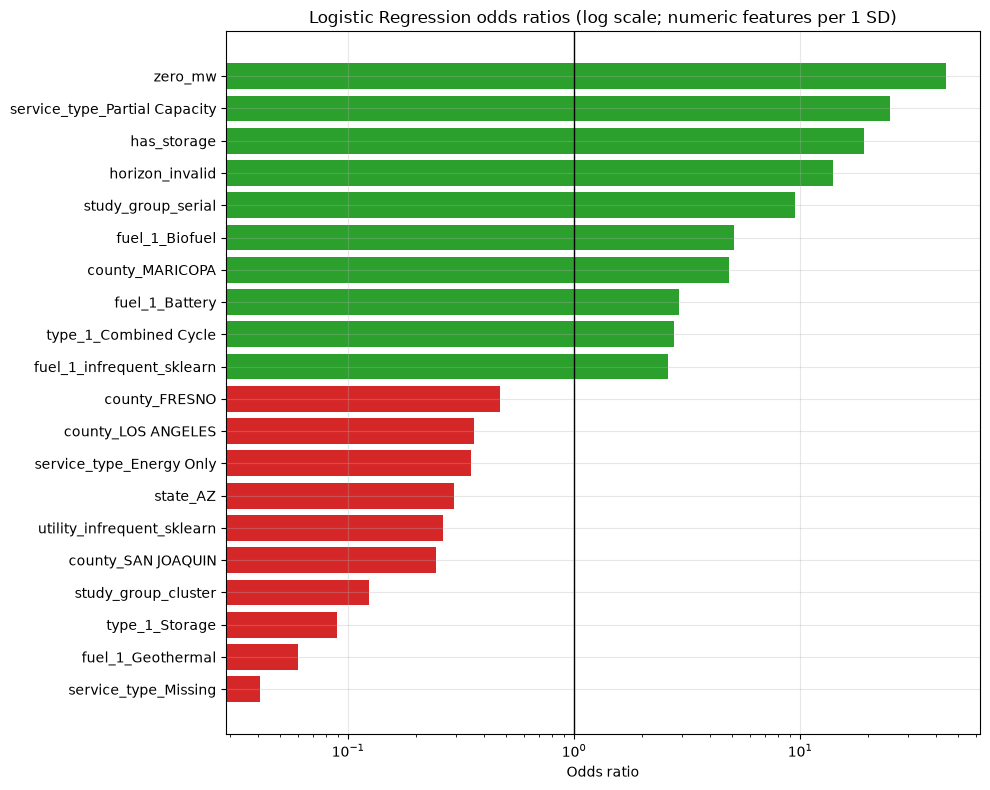

In [27]:
lr = tuned["Logistic Regression"]
lr_names = lr.named_steps["prep"].get_feature_names_out()
odds = (pd.DataFrame({"feature": lr_names, "coefficient": lr.named_steps["model"].coef_[0]})
        .assign(odds_ratio=lambda d: np.exp(d["coefficient"]))
        .sort_values("coefficient"))
top_odds = pd.concat([odds.head(10), odds.tail(10)])
print("Logistic Regression: 10 most negative and 10 most positive associations (uncalibrated model fit on train)")
display(top_odds)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top_odds["feature"], top_odds["odds_ratio"], color=np.where(top_odds["odds_ratio"] > 1, "tab:green", "tab:red"))
ax.axvline(1, color="k", lw=1)
ax.set_xscale("log")
ax.set(title="Logistic Regression odds ratios (log scale; numeric features per 1 SD)", xlabel="Odds ratio")
fig.tight_layout()
plt.show()

**Interpretation (Logistic Regression; associations, not causes).**
* **Ignore the largest odds ratios.** `zero_mw` (44) and `horizon_invalid` (14) rest on 2-4 projects each. With weak
  regularization (C = 6.4) these estimates are unstable.
* **Reading the categorical terms:** one-hot encoding here keeps every category, so each category's odds ratio is a *contrast
  with the other categories of the same field* rather than with a single reference level.
* **Positive associations:** `has_storage` (19x), `service_type = Partial Capacity` (25x), `study_group = serial` (9.5x, relative
  to other study paths once the other features are held fixed), and battery and biofuel fuels.
* **Negative associations:** `service_type = Missing` (0.04, an older-era marker), `study_group = cluster` (0.12), geothermal,
  `type_1 = Storage` (0.09), Energy Only (0.35), and some counties (San Joaquin, Los Angeles, Fresno).
* **`type_1 = Storage` and `has_storage` point in opposite directions** because they overlap. Together they suggest that
  *stand-alone* storage did worse than storage *paired with generation*.

Remember that Logistic Regression is the weakest model here (test PR-AUC 0.36). Its coefficients are a readable summary, not
the final model's logic.

Permutation importance for Random Forest (test set, PR-AUC drop when a feature is shuffled)


,feature,pr_auc_drop_mean,pr_auc_drop_std
0,study_group,0.083,0.016
1,service_type,0.057,0.024
2,requested_horizon_years,0.052,0.014
3,has_storage,0.045,0.027
4,poi_kv,0.031,0.020
5,n_components,0.017,0.009
6,type_1,0.016,0.006
7,log_net_mw,0.014,0.011
8,horizon_invalid,0.012,0.003
9,county,0.010,0.011


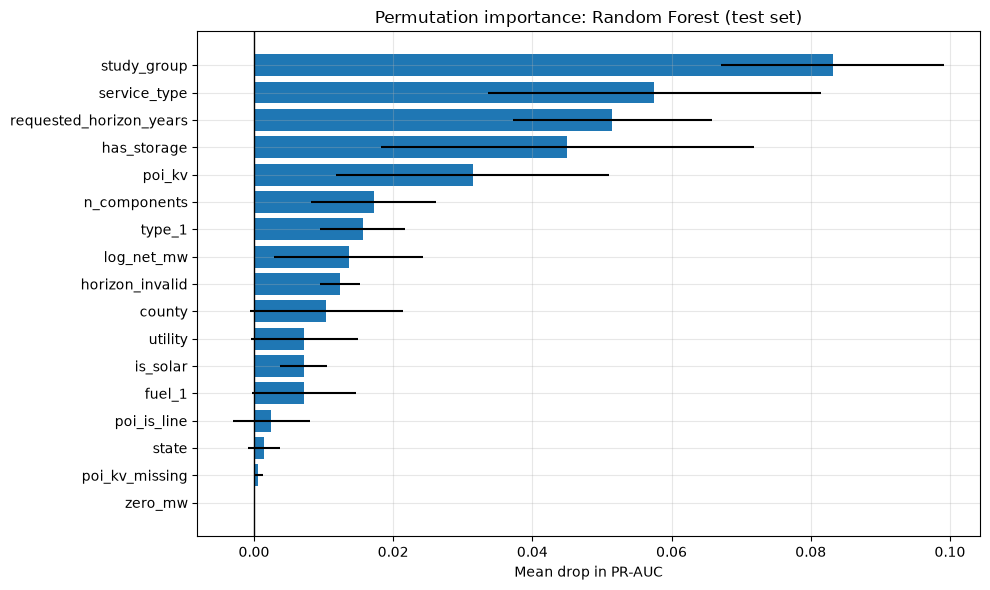

In [28]:
perm = permutation_importance(calibrated[FINAL_MODEL], X_test, y_test, scoring="average_precision",
                              n_repeats=20, random_state=SEED)
perm_table = (pd.DataFrame({"feature": FEATURES, "pr_auc_drop_mean": perm.importances_mean,
                            "pr_auc_drop_std": perm.importances_std})
              .sort_values("pr_auc_drop_mean", ascending=False).reset_index(drop=True))
print(f"Permutation importance for {FINAL_MODEL} (test set, PR-AUC drop when a feature is shuffled)")
display(perm_table)

fig, ax = plt.subplots(figsize=(10, 6))
plot_perm = perm_table.iloc[::-1]
ax.barh(plot_perm["feature"], plot_perm["pr_auc_drop_mean"], xerr=plot_perm["pr_auc_drop_std"], color="tab:blue")
ax.axvline(0, color="k", lw=1)
ax.set(title=f"Permutation importance: {FINAL_MODEL} (test set)", xlabel="Mean drop in PR-AUC")
fig.tight_layout()
plt.show()

**Interpretation (Random Forest, test set).** Shuffling **`study_group`** costs the most PR-AUC (0.083), followed by
`service_type` (0.057), `requested_horizon_years` (0.052), `has_storage` (0.045), and `poi_kv` (0.031). Location fields
(county, utility, state) contribute little individually.

Two of the top features carry era information: serial study processes and missing service types belong to the older era.
Part of their importance is therefore "which era was this," the same issue as in Section 14. The standard deviations are large
relative to the means below the top five, so the order of the lower-ranked features is not reliable.

CatBoost: mean |SHAP| on the test set (top 15)


,mean_abs_shap
poi_kv,0.574
log_net_mw,0.537
service_type,0.333
requested_horizon_years,0.273
utility,0.231
study_group,0.229
has_storage,0.208
poi_is_line,0.177
county,0.152
fuel_1,0.125


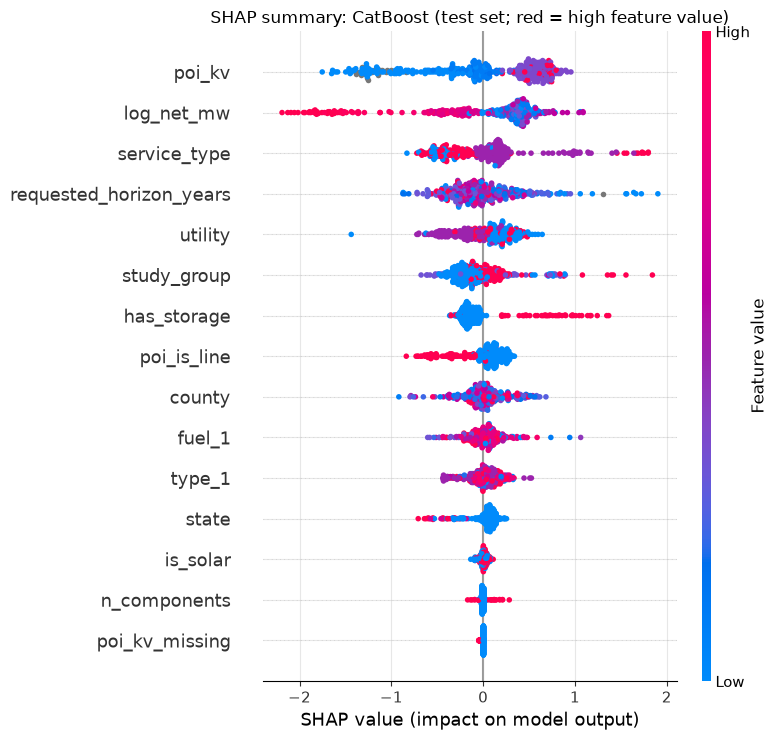

In [29]:
tree = tuned[BEST_TREE]
if BEST_TREE == "CatBoost":
    cb = tree.named_steps["model"].model_
    shap_values = cb.get_feature_importance(Pool(X_test, cat_features=CATEGORICAL), type="ShapValues")[:, :-1]
    shap_features = X_test.copy()
    for col in CATEGORICAL:
        shap_features[col] = shap_features[col].astype("category").cat.codes  # colour scale only
else:
    prep = tree.named_steps["prep"]
    shap_features = pd.DataFrame(prep.transform(X_test), columns=prep.get_feature_names_out())
    shap_values = shap.TreeExplainer(tree.named_steps["model"]).shap_values(shap_features)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif np.ndim(shap_values) == 3:
        shap_values = shap_values[:, :, 1]

shap_rank = (pd.Series(np.abs(shap_values).mean(axis=0), index=shap_features.columns)
             .sort_values(ascending=False).to_frame("mean_abs_shap"))
print(f"{BEST_TREE}: mean |SHAP| on the test set (top 15)")
display(shap_rank.head(15))
shap.summary_plot(shap_values, shap_features, max_display=15, show=False)
plt.title(f"SHAP summary: {BEST_TREE} (test set; red = high feature value)")
plt.tight_layout()
plt.show()

**Interpretation (CatBoost, test set).** The features that move individual predictions most are:
* **Point-of-interconnection voltage:** high voltage pushes predictions up, low voltage down.
* **Project size:** large projects (red points on `log_net_mw`) are pushed down, some strongly.
* **`service_type` and `study_group`.**
* **`has_storage`:** having storage pushes predictions up.
* **`poi_is_line`:** tapping a transmission line rather than a substation pushes predictions down.
* **Requested horizon:** very short requests sometimes push predictions up.

For categorical features, the colors are arbitrary category codes, so only the spread is meaningful.

The rankings differ somewhat from permutation importance (CatBoost leans more on voltage and size; Random Forest more on
study group). Correlated features share credit differently in different models, so treat the top six or seven features as the
robust set rather than any exact order.

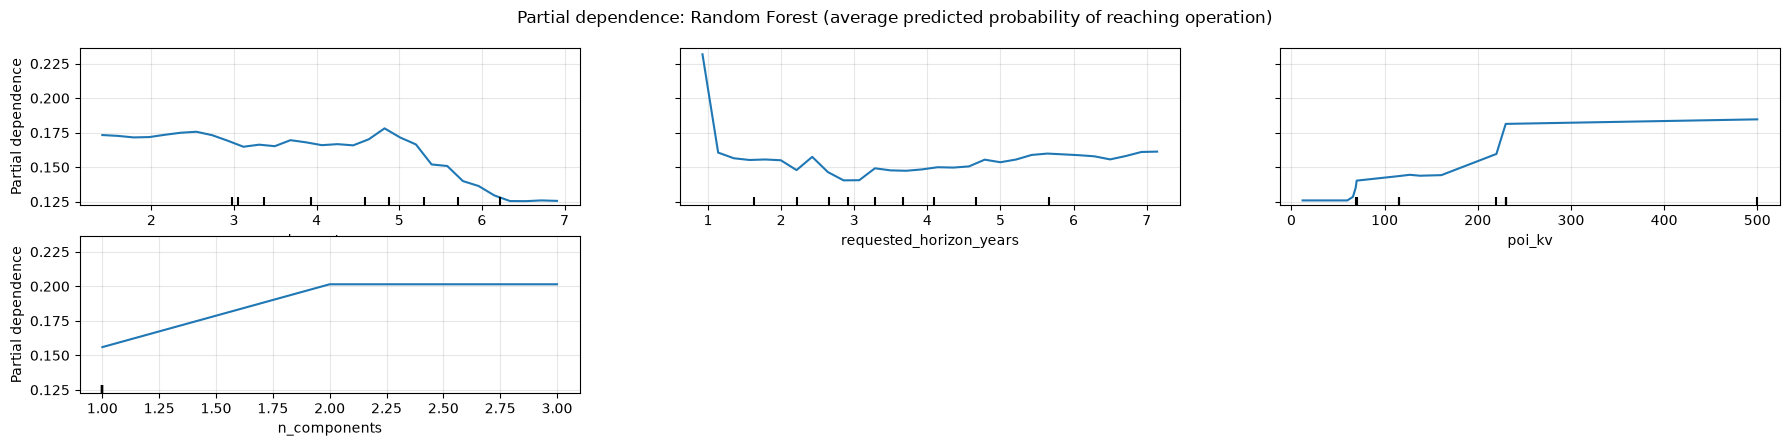

In [30]:
pdp_features = [c for c in ["log_net_mw", "requested_horizon_years", "poi_kv", "n_components", "queue_year"] if c in FEATURES]
fig, ax = plt.subplots(figsize=(4.5 * len(pdp_features), 4.5))
PartialDependenceDisplay.from_estimator(calibrated[FINAL_MODEL], X_train.astype({c: float for c in NUMERIC}), pdp_features, kind="average",
                                        response_method="predict_proba", grid_resolution=30,
                                        percentiles=(0.02, 0.98), ax=ax)
fig.suptitle(f"Partial dependence: {FINAL_MODEL} (average predicted probability of reaching operation)")
fig.tight_layout()
plt.show()

**Interpretation (Random Forest, averaged over training projects).**
* **Size:** the predicted probability is flat around 0.17 up to about 150 MW (`log_net_mw` near 5), then declines to about
  0.13 above about 500 MW.
* **Requested horizon:** very short requests (under about 1.2 years) average about 0.23, while longer horizons sit around 0.15.
  These are often small, nearly ready projects.
* **Voltage:** projects at 230 kV and above average about 0.18, versus 0.13 below 70 kV.
* **Components:** two or more components average 0.20 versus 0.16 for one.

The effects are moderate, a few percentage points each, consistent with the weak single-feature AUCs. They are associations.
For example, high voltage may stand for transmission-rich locations or larger, better-capitalized developers rather than
voltage itself helping.

## 16. Model selection, saved artifacts, and the scoring helper

**Purpose.** Confirm the selected model, save it with everything the agent needs to use it correctly, and demonstrate the
scoring contract.

**Why it matters.** The agent's ML tool must reproduce the training feature logic exactly, know the maturity cutoff (to warn
when a project is outside the training period), and apply the same tier thresholds. Saving these in metadata prevents silent
mismatches.

**Artifacts written to `Models/`.**
* `caiso_c14_classifier.joblib`: the calibrated, selected pipeline (preprocessing plus model). Loading it requires
  `Scripts/caiso_ml_data.py` on the Python path, because the pipeline uses its `QuantileClipper`.
* `model_metadata.json`: features, dropped features and reasons, cutoff year and rule, tolerances examined, thresholds by
  criterion, tier thresholds, OOF and test metrics, hyperparameters, data fingerprint, library versions, and `model_version`.
* `validation_holdout_ids.csv`: the frozen validation projects (written in Section 4).

**Scoring helper.** `cd.score_projects(model, metadata, projects)` takes cleaned project records and returns, per project, the
probability of reaching operation before withdrawal, the risk tier, the model version, and caveats.

In [31]:
selection_view = oof_table.loc[list(MODEL_SPECS), ["pr_auc", "roc_auc", "brier", "log_loss", "solar_pr_auc",
                                                   "cv_pr_auc_fold_std"]].add_prefix("oof_")
selection_view = selection_view.join(test_all.loc[list(MODEL_SPECS), ["pr_auc", "roc_auc", "brier"]].add_prefix("test_"))
selection_view = selection_view.join(test_solar.loc[list(MODEL_SPECS), ["pr_auc"]].add_prefix("test_solar_"))
selection_view["selected"] = selection_view.index == FINAL_MODEL
display(selection_view)
print("Selected (rule fixed in Section 10, OOF metrics only):", FINAL_MODEL)

,oof_pr_auc,oof_roc_auc,oof_brier,oof_log_loss,oof_solar_pr_auc,oof_cv_pr_auc_fold_std,test_pr_auc,test_roc_auc,test_brier,test_solar_pr_auc,selected
model,,,,,,,,,,,
Logistic Regression,0.400,0.721,0.116,0.387,0.534,0.100,0.363,0.728,0.119,0.458,False
Random Forest,0.522,0.799,0.100,0.339,0.567,0.132,0.455,0.753,0.113,0.612,True
XGBoost,0.505,0.790,0.102,0.342,0.616,0.080,0.408,0.722,0.115,0.568,False
CatBoost,0.529,0.795,0.100,0.340,0.612,0.112,0.454,0.741,0.112,0.575,False


Selected (rule fixed in Section 10, OOF metrics only): Random Forest


**Interpretation.** The pre-set rule chose **Random Forest**, and the test set confirms it is among the best. Its test PR-AUC
is 0.455 versus 0.454 for CatBoost, and its Brier score 0.113 versus 0.112: a tie. Both clearly beat XGBoost and Logistic
Regression. The choice was not revisited after seeing test results, which keeps the test estimate honest.

**One documented trade-off.** In the time-based check (Section 14), CatBoost's probability level held up better on later
cohorts (Brier 0.116 vs. 0.173). If well-calibrated levels for new cohorts become the priority, CatBoost is the natural
alternative, but neither model should be trusted on level without recalibration on newer data.

In [32]:
def to_jsonable(obj):
    # Convert numpy and pandas scalars so json.dump can serialize metadata.
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, float) and np.isnan(obj):
        return None
    return obj


MODEL_PATH = MODELS_DIR / "caiso_c14_classifier.joblib"
METADATA_PATH = MODELS_DIR / "model_metadata.json"
MODEL_VERSION = f"caiso-c14-realization-v1.0-{date.today():%Y%m%d}"
prob_keys = ["base_rate", "roc_auc", "pr_auc", "brier", "log_loss"]
cls_keys = ["threshold", "accuracy", "precision", "recall", "f1", "balanced_accuracy", "mcc", "tp", "fp", "fn", "tn"]

metadata = {
    "model_version": MODEL_VERSION,
    "model_name": FINAL_MODEL,
    "created": date.today().isoformat(),
    "target": {"name": cd.TARGET,
               "definition": "1 = reached commercial operation (Completed sheet); 0 = withdrawn (Withdrawn sheet)",
               "prediction": "Calibrated probability of reaching commercial operation before withdrawal",
               "not": "An approval/rejection forecast or an investment-underwriting decision"},
    "features": FEATURES, "numeric_features": NUMERIC, "binary_features": BINARY, "categorical_features": CATEGORICAL,
    "dropped_features": DROP_FEATURES,
    "excluded_leakage_columns": cd.LEAKAGE_COLUMNS,
    "maturity_cutoff_year": CUTOFF_YEAR,
    "maturity_cutoff_rule": CUTOFF_RULE,
    "maturity_tolerance": MAIN_TOLERANCE,
    "tolerances_examined": cutoff_table.to_dict(orient="records"),
    "training_cohort": {"mature_projects": len(mature), "mature_operational": int(mature[cd.TARGET].sum()),
                        "immature_projects_excluded": len(immature),
                        "train": len(train_df), "test": len(test_df), "validation": len(val_df),
                        "split": "stratified by reached_operation x is_solar, 60/30/10", "seed": SEED},
    "calibration": "CalibratedClassifierCV(method='sigmoid', cv=5-fold stratified)",
    "hyperparameters": {k: str(v) for k, v in searches[FINAL_MODEL].best_params_.items()},
    "thresholds": {"source": "out-of-fold training predictions", **final_thresholds},
    "tier_thresholds": {"low": TIER_LOW, "high": TIER_HIGH,
                        "low_rule": "recall_90: highest OOF threshold keeping 90% recall",
                        "high_rule": "max_f0_5: OOF threshold maximizing F0.5 (precision-weighted)"},
    "metrics": {
        "oof_train": {k: oof_table.loc[FINAL_MODEL, k] for k in prob_keys},
        "test_all_technologies": {**{k: test_all.loc[FINAL_MODEL, k] for k in prob_keys},
                                  "at_max_f1": {k: test_all.loc[FINAL_MODEL, k] for k in cls_keys}},
        "test_solar_directional": {**{k: test_solar.loc[FINAL_MODEL, k] for k in prob_keys},
                                   "at_max_f1": {k: test_solar.loc[FINAL_MODEL, k] for k in cls_keys}},
        "bootstrap_95ci_test_all": boot_all.drop(columns="subset").to_dict(orient="records"),
        "bootstrap_95ci_test_solar": boot_solar.drop(columns="subset").to_dict(orient="records"),
    },
    "data": {"file": DATA_PATH.name, "sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()},
    "libraries": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "xgboost": xgboost.__version__, "catboost": catboost.__version__, "pandas": pd.__version__},
    "loading_note": "Requires Scripts/caiso_ml_data.py on sys.path (QuantileClipper); score with caiso_ml_data.score_projects.",
    "caveats": [
        "Associations, not causes.",
        "Trained on projects queued in or before the cutoff year; newer projects are extrapolation.",
        "Solar metrics are directional (small test sample).",
        "Development/interconnection realization risk only; excludes offtake, financing, resource, and O&M risk.",
    ],
}

joblib.dump(calibrated[FINAL_MODEL], MODEL_PATH)
METADATA_PATH.write_text(json.dumps(to_jsonable(metadata), indent=2))
print(f"Saved {MODEL_PATH} and {METADATA_PATH} (model_version {MODEL_VERSION})")

Saved ../Models/caiso_c14_classifier.joblib and ../Models/model_metadata.json (model_version caiso-c14-realization-v1.0-20261005)


**Interpretation.** The model file and the metadata are written to `Models/`. The metadata records everything needed to use and
audit the model: the 17 features, the three dropped features with their reasons, the 2016 cutoff and its rule, all threshold
criteria, tier thresholds (0.07 / 0.56), OOF and test metrics with bootstrap intervals, hyperparameters, a SHA-256 fingerprint
of the source workbook, and library versions. The model file is about 12 MB because Random Forest stores 400 trees, and each
is copied inside the 5 calibration folds.

In [33]:
# Reload from disk exactly as the agent's ML tool would, then score examples.
loaded_model = joblib.load(MODEL_PATH)
loaded_meta = json.loads(METADATA_PATH.read_text())
assert np.allclose(loaded_model.predict_proba(X_test)[:, 1], p_final), "Reloaded model gives different predictions."

active_c14 = projects[(projects["outcome"] == "active") & (projects["study_process"].astype(str).str.strip() == "C14")]
examples = pd.concat([test_df.head(3), active_c14[active_c14["is_solar"]].head(3)])
scored = cd.score_projects(loaded_model, loaded_meta, examples)
scored = scored.merge(examples[[cd.ID_COLUMN, "outcome", "fuel_1", "queue_year", "net_mw_to_grid"]], on=cd.ID_COLUMN)
with pd.option_context("display.max_colwidth", 200):
    display(scored)

print("Risk-tier distribution for active Cluster 14 projects (all technologies):")
active_scores = cd.score_projects(loaded_model, loaded_meta, active_c14)
display(active_scores["risk_tier"].value_counts().to_frame("projects"))
print(f"Mean predicted probability, active Cluster 14: {active_scores['probability_reaching_operation'].mean():.3f}")

,queue_position,probability_reaching_operation,risk_tier,model_version,caveats,outcome,fuel_1,queue_year,net_mw_to_grid
0,187,0.082,moderate realization likelihood,caiso-c14-realization-v1.0-20261005,"[Probability of reaching commercial operation before withdrawal; not an approval forecast., Based on historical associations, not causes.]",withdrawn,Geothermal,2007,50.000
1,598,0.093,moderate realization likelihood,caiso-c14-realization-v1.0-20261005,"[Probability of reaching commercial operation before withdrawal; not an approval forecast., Based on historical associations, not causes.]",withdrawn,Solar,2010,17.750
2,42,0.077,moderate realization likelihood,caiso-c14-realization-v1.0-20261005,"[Probability of reaching commercial operation before withdrawal; not an approval forecast., Based on historical associations, not causes.]",withdrawn,Natural Gas,2004,300.000
3,1935,0.661,higher realization likelihood,caiso-c14-realization-v1.0-20261005,"[Probability of reaching commercial operation before withdrawal; not an approval forecast., Based on historical associations, not causes., Project queued in 2021, after the training cutoff (2016);...",active,Solar,2021,200.000
4,1943,0.528,moderate realization likelihood,caiso-c14-realization-v1.0-20261005,"[Probability of reaching commercial operation before withdrawal; not an approval forecast., Based on historical associations, not causes., Project queued in 2021, after the training cutoff (2016);...",active,Solar,2021,1150.000
5,1952,0.761,higher realization likelihood,caiso-c14-realization-v1.0-20261005,"[Probability of reaching commercial operation before withdrawal; not an approval forecast., Based on historical associations, not causes., Project queued in 2021, after the training cutoff (2016);...",active,Solar,2021,300.000


Risk-tier distribution for active Cluster 14 projects (all technologies):


,projects
risk_tier,
moderate realization likelihood,78
higher realization likelihood,26


Mean predicted probability, active Cluster 14: 0.425


**Interpretation.** The reloaded model reproduces the in-notebook predictions exactly, so the saved artifact is what was
evaluated. `cd.score_projects` returns the contract the agent's ML tool needs: probability, tier, model version, and caveats.

* Three test projects (all withdrew) score 0.08-0.09, in the moderate tier.
* Three active Cluster 14 solar projects score 0.53-0.76, and each carries the post-cutoff caveat.
* **All 104 active Cluster 14 projects:** 26 higher, 78 moderate, 0 lower, mean probability **0.425**. That is far above any
  historical cohort rate (about 15%).

Per Section 14, read this as *"these projects match the profile that historically did well: storage-paired, high-voltage, full
capacity,"* not as "42% of Cluster 14 will reach operation."

Separately, active Cluster 14 projects have already survived about five years in the queue. This model predicts from queue
entry and ignores that survival, which should genuinely raise their odds. That is exactly the question a competing-risks
survival model would answer properly.

In [34]:
# Final QA assertions (the build plan's checklist).
all_split_ids = [set(f[cd.ID_COLUMN]) for f in (train_df, test_df, val_df)]
assert not (all_split_ids[0] & all_split_ids[1]) and not (all_split_ids[0] & all_split_ids[2]) and not (all_split_ids[1] & all_split_ids[2])
assert all((f["outcome"] != "active").all() for f in (train_df, test_df, val_df)), "Active project in a labeled set"
assert all((f["queue_year"] <= CUTOFF_YEAR).all() for f in (train_df, test_df, val_df)), "Post-cutoff project in a labeled set"
assert not set(FEATURES) & set(cd.LEAKAGE_COLUMNS), "Leakage column in features"
assert set(pd.read_csv(HOLDOUT_PATH)[cd.ID_COLUMN].astype(str)) == set(val_df[cd.ID_COLUMN].astype(str))
assert test_all.loc[FINAL_MODEL, "pr_auc"] > test_all.loc["Dummy (base rate)", "pr_auc"], "Selected model does not beat the baseline (PR-AUC)"
assert test_all.loc[FINAL_MODEL, "brier"] < test_all.loc["Dummy (base rate)", "brier"], "Selected model does not beat the baseline (Brier)"
assert loaded_meta["maturity_cutoff_year"] == CUTOFF_YEAR and loaded_meta["features"] == FEATURES
print("All QA assertions passed.")

All QA assertions passed.


## 17. Final thoughts and recommendations

**What was built.** A leakage-safe, calibrated classifier estimating the **probability that a CAISO interconnection project
reaches commercial operation before it withdraws**:
* trained on 821 resolved projects queued in or before **2016**;
* the cutoff was chosen from the active sheet's label-maturity diagnostic (10% unresolved tolerance);
* evaluated once on 412 test projects;
* 137 projects are held out for the agent.

**Headline results (Random Forest, test set).**

| Metric | All technologies | Solar (directional) | Dummy baseline |
|---|---|---|---|
| PR-AUC | 0.455 (95% CI 0.33-0.59) | 0.61 (0.46-0.76) | 0.155 |
| ROC-AUC | 0.753 (0.67-0.83) | 0.86 (0.79-0.93) | 0.500 |
| Brier score | 0.113 | 0.095 | 0.131 |
| Top-decile precision (lift) | 51% (3.3x) | 63% (4.1x) | 15.5% (1.0x) |

**Key judgment calls (all documented above).**
1. **Maturity cutoff at 2016.** Ranking accuracy is robust to the cutoff, but prediction *levels* for recent projects are not
   (Section 14).
2. **Dropped `days_ir_to_queue`** (withdrawn-sheet recording artifact), **`is_hybrid`** (duplicate of `n_components`), and
   **`queue_year`** (era proxy below the pre-set ablation bar).
3. **Sigmoid calibration** on every model; thresholds chosen on out-of-fold training predictions only.
4. **Model selection by a rule fixed before testing.** Random Forest and CatBoost are effectively tied.

**On the "maximize TP, minimize FP" objective.** Its formal version (Youden's J) assumes the two error rates cost the same.
Investors usually weight false positives more and developers false negatives more. The agent should therefore report the
**calibrated probability plus a risk tier** (lower below 0.07, higher at 0.56 and above) and apply a hard threshold only when a
user states a cost ratio.

**Main limitation: distribution shift.** Storage went from 2% of early projects to 99% of active Cluster 14, project sizes
tripled, and study rules changed. In a time-based test, the model kept its ranking power but over-predicted the later period's
level (0.37 predicted vs. 0.13 observed). For Cluster 15 and active Cluster 14, **treat scores as relative rankings among
peers**, and let the SQL tool supply current base rates and comparables.

**Validation holdout and agent evaluation.**
* **Size:** 137 projects (21 operational, 12 operational solar). That is too small for precise metrics (AUC intervals of about
  +/- 0.10) but suitable for **end-to-end agent evaluation**: correct tool calls, faithful explanations, right tier, and
  appropriate caveats.
* **Exclude holdout projects' own records from SQL comparables.** When the agent assesses a holdout project, its SQL tool must
  not retrieve that project's own record, outcome, or withdrawal reason. Otherwise the agent can read the answer. Filter the
  `queue_position` values in `Models/validation_holdout_ids.csv` out of comparable-project queries during evaluation, and ideally
  also any record of the same project under another name.
* **Inference cases are separate from evaluation cases.** Use **Cluster 15** projects and **post-cutoff projects** (active
  Cluster 14 and the immature cohort) as realistic *inference* examples that show how the agent handles out-of-period projects.
  They have no reliable labels, so they test behavior and caveats, not accuracy.

**Recommended next steps.**
1. **Competing-risks survival model** (time to operation vs. time to withdrawal) that uses active projects as censored
   observations and conditions on time already survived in the queue. This directly addresses both the maturity cutoff and
   the over-prediction for Cluster 14.
2. **Recalibrate as newer cohorts mature**, for example refitting the sigmoid on 2017-2019 projects once their active share falls
   below 10%.
3. **Report peer-relative rank** (percentile within the same cluster and technology) alongside the probability in the agent
   output.
4. **Add queue-entry context features** carefully: transmission-zone congestion and deliverability headroom at the requested
   POI, only as they were known at queue entry.
5. Keep CAISO production and curtailment data as **SQL and agent context** (market saturation and curtailment stress), not as
   model features.

**Scope reminder.** This is a development and interconnection realization signal. It is not an approval forecast and not an
investment-underwriting model: offtake, financing, equipment quality, resource quality, and O&M risks are outside it.